# 03 · Clustering: Gower distance + hierarchical clustering

**Research question:** What health, lifestyle, and environmental patterns are associated with children's screen-time levels?

**Method (approved):** Gower dissimilarity on 14 mixed-type features → hierarchical clustering (average linkage; complete linkage as comparison) on a stratified sample of 10,000 children → silhouette analysis → assignment of the remaining children → stability and sensitivity checks → cluster profiling.

**Status of this notebook:** Sections 0–6 set up and validate the method (data checks, feature specification, Gower implementation and validation, sampling, and a 2,000-child computational pilot). Sections 7–10 run the 10,000-child clustering, its evaluation for k = 2–10, the W1 weighting sensitivity, and the stability check across the five replicate samples. **Section 11 is the checkpoint**, and the decision (complete linkage, W0, k = 3) is recorded after it. Sections 12–15 then assign the remaining children, run the sensitivity checks, build cluster profiles and export the outputs.

> Screen time is a clustering *feature*, not a prediction target. Results describe associations in the survey sample, not causal effects.

## 0 · Setup and configuration

All tunable settings are defined once here so that every later step is reproducible.

- `SEED = 42` is used for every random operation (sampling, row shuffling).
- Memory is monitored for every heavy step: wall-clock time, the peak memory allocated *during* the step (`tracemalloc`, which tracks NumPy arrays), and the process's resident memory (RSS) before and after.
- `require_memory()` stops a step **before** a large allocation if the machine does not have enough free RAM, instead of letting Windows swap to disk.

In [1]:
import gc
import platform
import time
import tracemalloc
from contextlib import contextmanager
from pathlib import Path

import numpy as np
import pandas as pd
import psutil
import scipy
import sklearn
from scipy.cluster.hierarchy import cophenet, fcluster, is_monotonic, is_valid_linkage, linkage
from scipy.spatial.distance import squareform
from sklearn.metrics import silhouette_samples

# ---- Configuration -------------------------------------------------------
SEED = 42
SAMPLE_SIZE = 10_000              # children per replicate sample
N_PARTS = 5                       # disjoint stratified replicate samples (part 0 = primary)
PILOT_SIZE = 2_000                # real-data pilot (subsample of part 0)
STRATA_COLS = ["formtype", "screentime"]   # 3 x 5 = 15 strata
K_RANGE = list(range(2, 11))      # candidate numbers of clusters
LINKAGE_METHODS = ["average", "complete"]  # Ward/centroid/median excluded: they require Euclidean geometry
GOWER_BLOCK_ROWS = 500            # rows per block when building the distance matrix
ASSIGN_CHUNK_ROWS = 1_000         # rows per chunk when assigning non-sample children
AMBIGUITY_THRESHOLDS = (0.005, 0.01, 0.02)  # assignment-margin thresholds to compare (Gower units)
MIN_CLUSTER_SHARE = 0.01          # clusters < 1% of the sample are flagged and investigated (not discarded)
SILHOUETTE_GUIDELINE = 0.02       # practical comparison guideline, not a statistical threshold

DATA_PATH = Path.cwd() / "datasets" / "preprocessed_data.csv"
sklearn.set_config(working_memory=256)   # cap scikit-learn chunked computations at 256 MiB

print("Python  ", platform.python_version())
for mod in (np, pd, scipy, sklearn, psutil):
    print(f"{mod.__name__:8s}", mod.__version__)
vm = psutil.virtual_memory()
print(f"\nRAM total {vm.total / 2**30:.1f} GiB | available now {vm.available / 2**30:.2f} GiB | logical CPUs {psutil.cpu_count()}")

Python   3.12.7
numpy    1.26.4
pandas   2.2.2
scipy    1.13.1
sklearn  1.5.1
psutil   5.9.0

RAM total 13.8 GiB | available now 4.51 GiB | logical CPUs 16


In [2]:
# ---- Memory and runtime monitoring helpers --------------------------------
PROC = psutil.Process()
PERF_LOG = []          # one row per monitored step


def rss_mib():
    return PROC.memory_info().rss / 2**20


def available_mib():
    return psutil.virtual_memory().available / 2**20


def require_memory(n_bytes, label, factor=1.5):
    # Stop before allocating if free RAM is below factor x the expected requirement.
    need_mib = n_bytes * factor / 2**20
    if need_mib > available_mib():
        raise MemoryError(
            f"[{label}] needs ~{need_mib:,.0f} MiB (incl. x{factor} margin) but only "
            f"{available_mib():,.0f} MiB is free. Close other applications and re-run."
        )


@contextmanager
def monitor(step, **info):
    # Record wall time, peak traced allocation, and RSS for one step.
    gc.collect()
    rss_before = rss_mib()
    tracemalloc.start()
    t0 = time.perf_counter()
    try:
        yield
    finally:
        seconds = time.perf_counter() - t0
        _, peak = tracemalloc.get_traced_memory()
        tracemalloc.stop()
        PERF_LOG.append({
            "step": step, **info,
            "seconds": round(seconds, 3),
            "peak_alloc_mib": round(peak / 2**20, 1),
            "rss_before_mib": round(rss_before, 1),
            "rss_after_mib": round(rss_mib(), 1),
            "available_after_mib": round(available_mib(), 0),
        })

## 1 · Load and validate the processed dataset

**What:** load `datasets/preprocessed_data.csv` (exported by `01_preprocessing.ipynb`) and check its schema.

**Why:** every later step assumes a fixed set of columns, a unique identifier, and no ordinary missing values in the clustering features.

**Checks:**
- 51,375 rows; all expected column groups present.
- `hhid` is unique and complete (the stable child identifier; it is never a feature).
- The 15 processed variables have no missing values.
- `sleep_below_minimum` is missing **only** for infants under 4 months (`sc_age_lt4 = 1`). This is *structural* missingness: no sleep recommendation applies at that age. It is not nonresponse, so it is not imputed and does not make a child "incomplete".

In [3]:
df = pd.read_csv(DATA_PATH)

ID_COL = "hhid"
PROCESSED_VARS = ["sc_age_years", "sc_sex", "family_r", "blindness", "eyedoctor", "k4q22_r", "k4q23",
                  "screentime", "sleep_hours", "k6q71_r", "higrade", "foodsit", "k10q12", "k10q13", "k10q14"]
METADATA_COLS = ["formtype", "fwc", "fipsst", "stratum", "sc_age_lt4"]
DERIVED_COLS = ["sleep_below_minimum"]
FLAG_COLS = [c for c in df.columns if c.endswith("_imputed")]

expected = [ID_COL] + PROCESSED_VARS + METADATA_COLS + DERIVED_COLS
missing_cols = sorted(set(expected) - set(df.columns))
assert not missing_cols, f"Missing columns: {missing_cols}"
assert len(df) == 51_375, len(df)
assert df[ID_COL].is_unique and df[ID_COL].notna().all()
assert df[PROCESSED_VARS].notna().all().all()

# Structural missingness: sleep_below_minimum is NaN exactly for infants < 4 months
sleep_na = df["sleep_below_minimum"].isna()
under_4m = df["sc_age_lt4"].eq(1)
assert sleep_na.equals(under_4m), "sleep_below_minimum missingness does not match sc_age_lt4"
assert df.loc[under_4m, "sc_age_years"].eq(0).all()

print("Shape:", df.shape)
print("Imputation flags:", FLAG_COLS)
print(f"Structural missing in sleep_below_minimum (infants < 4 months): {int(sleep_na.sum())}")
print(df[["formtype"]].value_counts().sort_index().to_string())

Shape: (51375, 34)
Imputation flags: ['family_r_imputed', 'blindness_imputed', 'eyedoctor_imputed', 'k4q22_r_imputed', 'k4q23_imputed', 'screentime_imputed', 'sleep_hours_imputed', 'k6q71_r_imputed', 'foodsit_imputed', 'k10q12_imputed', 'k10q13_imputed', 'k10q14_imputed']
Structural missing in sleep_below_minimum (infants < 4 months): 446
formtype
T1          13841
T2          15574
T3          21960


## 2 · Feature specification (approved 14-feature model)

Each feature's **Gower type** determines how two children are compared on it:

| Type | Per-feature dissimilarity `d` | Used for |
|---|---|---|
| `numeric` / `ordinal` | `|x_i − x_j| / range`, using the **fixed codebook range** (ordinal codes used as ranks; Kaufman & Rousseeuw) | age; ordered response scales |
| `nominal` | 0 if same category, else 1 | unordered categories |
| `binary_sym` | 0 if same, else 1; a shared "No" **counts** as similarity | both values meaningful |
| `binary_asym` | as above, but a pair where **both are "No"** is left out of the comparison | "Yes" marks the presence of an uncommon state |

Fixed ranges (rather than ranges observed in a sample) make distances identical across every sample and in the assignment step.

**Combined distance** between children *i* and *j* (Gower, 1971):

$$ d(i,j) = \frac{\sum_k w_k\, \delta_{ijk}\, d_{ijk}}{\sum_k w_k\, \delta_{ijk}} $$

where $\delta_{ijk}=0$ if feature *k* is missing for either child (only `sleep_below_minimum` for infants < 4 months) or if *k* is asymmetric binary and both children are "No"; otherwise $\delta_{ijk}=1$.

**Exact meanings (2024 NSCH codebook):**
- `blindness`: *"Does this child have … blindness or problems with seeing, even when wearing glasses?"* Described as **vision difficulty (even with glasses)**.
- `k4q23`: *"During the past 12 months, has this child taken any medication because of difficulties with their emotions, concentration, or behavior?"* This is **parent-reported medication use**, not a diagnosis.
- `k10q12–14`: *"In your neighborhood, is/are there"* a park or playground / a recreation or community center or boys' and girls' club / a library or bookmobile (parent report).

**Documented caveats:**
- `sleep_below_minimum` is defined using **age-specific** thresholds while `sc_age_years` is also a feature, so some age-related information overlaps.
- `eyedoctor` is excluded from the primary model ("ever" for T1 vs "past 2 years" for T2/T3) and is tested only in a sensitivity run.
- The original `sleep_hours` codes are not comparable across forms and are not used for clustering.

**Weighting schemes:** W0 gives every feature weight 1. W1 (domain-balanced) gives each domain a total weight of 1, split equally among its features.

**Sensitivity variants** (defined here; run later): `all_symmetric` (every binary symmetric), `with_eyedoctor` (15 features), `no_sleep` (13 features, sleep removed).

In [4]:
FEATURE_TABLE = pd.DataFrame(
    [
        # feature,             domain,        gower_type,   min, max, absent, description
        ("sc_age_years",        "general",     "numeric",     0, 17, np.nan, "Age in years"),
        ("sc_sex",              "general",     "binary_sym",  1,  2, np.nan, "Sex (1 male, 2 female)"),
        ("family_r",            "general",     "nominal",     1,  8, np.nan, "Family structure (8 types)"),
        ("blindness",           "health",      "binary_asym", 1,  2, 2,    "Vision difficulty even with glasses (1 yes, 2 no)"),
        ("k4q22_r",             "health",      "nominal",     1,  3, np.nan, "Mental health professional treatment, past 12 months (yes / no but needed / no, not needed)"),
        ("k4q23",               "health",      "binary_asym", 1,  2, 2,    "Medication for emotions/concentration/behavior, past 12 months (1 yes, 2 no)"),
        ("screentime",          "lifestyle",   "ordinal",     1,  5, np.nan, "Weekday screen time (<1 h ... 4+ h)"),
        ("sleep_below_minimum", "lifestyle",   "binary_sym",  0,  1, np.nan, "Sleep below age-specific recommended minimum (1 yes, 0 no; missing < 4 months)"),
        ("k6q71_r",             "lifestyle",   "ordinal",     1,  4, np.nan, "Shows interest/curiosity in learning (always ... never)"),
        ("higrade",             "environment", "ordinal",     1,  3, np.nan, "Highest adult education (< HS, HS, > HS)"),
        ("foodsit",             "environment", "ordinal",     1,  4, np.nan, "Household food affordability (always nutritious ... often not enough)"),
        ("k10q12",              "environment", "binary_sym",  1,  2, np.nan, "Park or playground in neighborhood"),
        ("k10q13",              "environment", "binary_sym",  1,  2, np.nan, "Recreation/community center or boys' and girls' club in neighborhood"),
        ("k10q14",              "environment", "binary_sym",  1,  2, np.nan, "Library or bookmobile in neighborhood"),
    ],
    columns=["feature", "domain", "gower_type", "min", "max", "absent_code", "description"],
)
EYEDOCTOR_ROW = ("eyedoctor", "health", "binary_sym", 1, 2, np.nan, "Seen an eye doctor (T1: ever; T2/T3: past 2 years)")

# Which imputation flag tracks each feature (features without a flag never had missing values)
FLAG_SOURCE = {"sleep_below_minimum": "sleep_hours"}


def build_spec(variant="primary", weighting="W0"):
    # Return the feature specification (with weights and ranges) for one model variant.
    spec = FEATURE_TABLE.copy()
    if variant == "with_eyedoctor":
        spec = pd.concat([spec, pd.DataFrame([EYEDOCTOR_ROW], columns=spec.columns)], ignore_index=True)
    elif variant == "no_sleep":
        spec = spec[spec["feature"] != "sleep_below_minimum"].reset_index(drop=True)
    elif variant == "all_symmetric":
        spec.loc[spec["gower_type"] == "binary_asym", ["gower_type", "absent_code"]] = ["binary_sym", np.nan]
    elif variant != "primary":
        raise ValueError(variant)

    spec["range"] = spec["max"] - spec["min"]
    if weighting == "W0":
        spec["weight"] = 1.0
    elif weighting == "W1":
        spec["weight"] = 1.0 / spec.groupby("domain")["feature"].transform("count")
    else:
        raise ValueError(weighting)
    return spec


def complete_case_mask(data, spec):
    # True where none of the model's features was imputed. Uses ONLY the model's features' flags;
    # the structural NaN in sleep_below_minimum (infants < 4 months) is not nonresponse and is ignored.
    flags = []
    for f in spec["feature"]:
        flag = f"{FLAG_SOURCE.get(f, f)}_imputed"
        if flag in data.columns:
            flags.append(flag)
    return data[flags].eq(0).all(axis=1), flags


SPEC_PRIMARY = build_spec("primary", "W0")
display(SPEC_PRIMARY.assign(weight_W1=build_spec("primary", "W1")["weight"].round(3)))

,feature,domain,gower_type,min,max,absent_code,description,range,weight,weight_W1
0,sc_age_years,general,numeric,0,17,NaN,Age in years,17,1.0,0.333
1,sc_sex,general,binary_sym,1,2,NaN,"Sex (1 male, 2 female)",1,1.0,0.333
2,family_r,general,nominal,1,8,NaN,Family structure (8 types),7,1.0,0.333
3,blindness,health,binary_asym,1,2,2.0,"Vision difficulty even with glasses (1 yes, 2 no)",1,1.0,0.333
4,k4q22_r,health,nominal,1,3,NaN,"Mental health professional treatment, past 12 ...",2,1.0,0.333
5,k4q23,health,binary_asym,1,2,2.0,Medication for emotions/concentration/behavior...,1,1.0,0.333
6,screentime,lifestyle,ordinal,1,5,NaN,Weekday screen time (<1 h ... 4+ h),4,1.0,0.333
7,sleep_below_minimum,lifestyle,binary_sym,0,1,NaN,Sleep below age-specific recommended minimum (...,1,1.0,0.333
8,k6q71_r,lifestyle,ordinal,1,4,NaN,Shows interest/curiosity in learning (always ....,3,1.0,0.333
9,higrade,environment,ordinal,1,3,NaN,"Highest adult education (< HS, HS, > HS)",2,1.0,0.200


In [5]:
# ---- Validate observed values against the specification ------------------
all_features = pd.concat([FEATURE_TABLE, pd.DataFrame([EYEDOCTOR_ROW], columns=FEATURE_TABLE.columns)])
for row in all_features.itertuples():
    vals = df[row.feature].dropna()
    assert vals.between(row.min, row.max).all(), f"{row.feature}: values outside {row.min}-{row.max}"
    assert (vals % 1 == 0).all(), f"{row.feature}: non-integer codes"
    if row.gower_type.startswith("binary"):
        assert set(vals.unique()) <= {row.min, row.max}, row.feature
    nan_ok = row.feature == "sleep_below_minimum"
    assert nan_ok or df[row.feature].notna().all(), f"{row.feature}: unexpected missing values"
print("All feature values lie within their codebook ranges.")

# ---- Complete-case counts (actual model features only) --------------------
for variant in ["primary", "with_eyedoctor", "no_sleep", "all_symmetric"]:
    spec = build_spec(variant)
    mask, flags = complete_case_mask(df, spec)
    print(f"{variant:15s} {len(spec):2d} features | complete cases: {int(mask.sum()):,} | flags used: {len(flags)}")

cc_primary, _ = complete_case_mask(df, build_spec("primary"))
cc_eye, _ = complete_case_mask(df, build_spec("with_eyedoctor"))
assert int(cc_primary.sum()) == 47_391 and int(cc_eye.sum()) == 47_260
print("\nInfants < 4 months counted as complete (primary):", int((cc_primary & under_4m).sum()), "of", int(under_4m.sum()))

All feature values lie within their codebook ranges.
primary         14 features | complete cases: 47,391 | flags used: 11
with_eyedoctor  15 features | complete cases: 47,260 | flags used: 12
no_sleep        13 features | complete cases: 47,497 | flags used: 10
all_symmetric   14 features | complete cases: 47,391 | flags used: 11

Infants < 4 months counted as complete (primary): 366 of 446


## 3 · Gower distance implementation

No external Gower package is used. The PyPI `gower` package has no ordinal or asymmetric-binary type, and it would treat integer-coded nominal variables as numeric. The implementation below is plain NumPy so every rule above is explicit.

- `gower_cross(XA, XB, spec)`: dissimilarities between every row of `XA` and every row of `XB` (a rectangular block).
- `gower_condensed(X, spec)`: all unique pairs within `X` as a condensed vector, built block by block. This is the format `scipy.cluster.hierarchy.linkage` expects. Memory is n(n−1)/2 × 8 bytes (≈ 381 MiB for n = 10,000), plus one block of temporaries.
- `mean_distance_to_clusters(...)`: for assignment, the **average** Gower distance from each new child to the members of each sample cluster, processed in chunks so a 41,375 × 10,000 matrix is never stored.

**Assignment margin** (used later): for child *x*, $D_c(x) = \frac{1}{|S_c|}\sum_{s\in S_c} d(x,s)$ for each cluster *c* with sample members $S_c$. The child is assigned to the cluster with the smallest $D_c$. Margin = second-smallest $D_c$ − smallest $D_c$, in Gower units (0–1 scale). Exact ties go to the lowest cluster label and are flagged.

**Memory-efficient helpers:**
- `condensed_to_square_float32`: the square matrix needed by silhouette, built without intermediate copies.
- `cophenetic_correlation`: computed in chunks, because scipy's `cophenet(Z, Y)` needs about six condensed-size arrays (about 2.3 GiB at n = 10,000).

**Failure modes guarded against:** a zero denominator (impossible here because most features are never missing or asymmetric, but asserted anyway), NaN leaking into distances, and running out of memory (`require_memory`).

In [6]:
def encode(data, spec):
    # Feature matrix (float64; NaN only for structural missingness), columns in spec order.
    return data[spec["feature"].tolist()].to_numpy(dtype=np.float64)


def gower_cross(XA, XB, spec):
    # Gower dissimilarities between rows of XA (m x p) and rows of XB (n x p) -> (m x n) float64.
    num = np.zeros((XA.shape[0], XB.shape[0]))
    den = np.zeros_like(num)
    for k, f in enumerate(spec.itertuples(index=False)):
        a = XA[:, k][:, None]
        b = XB[:, k][None, :]
        if f.gower_type in ("numeric", "ordinal"):
            d = np.abs(a - b) / f.range
        else:  # nominal, binary_sym, binary_asym: simple matching
            d = (a != b).astype(np.float64)
        valid = ~(np.isnan(a) | np.isnan(b))
        if f.gower_type == "binary_asym":
            valid = valid & ~((a == f.absent_code) & (b == f.absent_code))
        num += f.weight * np.where(valid, d, 0.0)
        den += f.weight * valid
    if not (den > 0).all():
        raise ValueError("Zero Gower denominator: a pair has no comparable features")
    return num / den


def gower_condensed(X, spec, block_rows=GOWER_BLOCK_ROWS):
    # Condensed Gower distance vector (scipy order: (0,1), (0,2), ..., (1,2), ...).
    n = X.shape[0]
    out_bytes = n * (n - 1) // 2 * 8
    block_bytes = block_rows * n * 8 * 6          # num, den, d, valid and temporaries
    require_memory(out_bytes + block_bytes, label=f"gower_condensed n={n}")
    out = np.empty(n * (n - 1) // 2, dtype=np.float64)
    pos = 0
    for start in range(0, n - 1, block_rows):
        stop = min(start + block_rows, n)
        block = gower_cross(X[start:stop], X[start:], spec)   # columns start .. n-1
        for r in range(stop - start):
            row = block[r, r + 1:]                           # j = i+1 .. n-1
            out[pos:pos + row.size] = row
            pos += row.size
    assert pos == out.size
    return out


def mean_distance_to_clusters(X_new, X_ref, label_sets, spec, chunk_rows=ASSIGN_CHUNK_ROWS):
    # For each labelling in label_sets {name: labels of X_ref}, return {name: (clusters, D)} where
    # D[i, c] = average Gower distance from X_new[i] to the reference members of cluster c.
    # The distance block for each chunk is computed once and reused for every labelling.
    require_memory(chunk_rows * X_ref.shape[0] * 8 * 6, label="assignment chunk")
    prepared = {}
    for name, labels in label_sets.items():
        clusters = np.unique(labels)
        onehot = (labels[:, None] == clusters[None, :]).astype(np.float64)
        prepared[name] = (clusters, onehot, onehot.sum(axis=0))
    out = {name: np.empty((X_new.shape[0], len(c))) for name, (c, _, _) in prepared.items()}
    for s in range(0, X_new.shape[0], chunk_rows):
        block = gower_cross(X_new[s:s + chunk_rows], X_ref, spec)
        for name, (clusters, onehot, sizes) in prepared.items():
            out[name][s:s + chunk_rows] = (block @ onehot) / sizes
    return {name: (prepared[name][0], D) for name, D in out.items()}


def condensed_to_square_float32(d):
    # Build the square float32 matrix directly from the condensed vector, one row at a time,
    # avoiding the extra float32 copy of the condensed vector that squareform(d.astype(float32)) makes.
    n = int(round((1 + np.sqrt(1 + 8 * d.size)) / 2))
    require_memory(n * n * 4, label=f"square float32 n={n}")
    D = np.zeros((n, n), dtype=np.float32)
    pos = 0
    for i in range(n - 1):
        row = d[pos:pos + n - 1 - i]
        D[i, i + 1:] = row
        D[i + 1:, i] = row
        pos += row.size
    return D


def cophenetic_correlation(Z, d, chunk=5_000_000):
    # Pearson correlation between cophenetic and Gower distances, computed in chunks.
    # scipy's cophenet(Z, Y) creates ~6 condensed-size temporaries (~2.3 GiB at n = 10,000);
    # this version needs only the cophenetic vector itself plus small chunks.
    c = cophenet(Z)
    mc, md = c.mean(), d.mean()
    sxy = sxx = syy = 0.0
    for s in range(0, d.size, chunk):
        a = c[s:s + chunk] - mc
        b = d[s:s + chunk] - md
        sxy += a @ b
        sxx += a @ a
        syy += b @ b
    return sxy / np.sqrt(sxx * syy)


def assign_from_distances(clusters, D):
    # Nearest cluster by average distance, the margin to the runner-up, and a tie indicator.
    order = np.argsort(D, axis=1, kind="stable")   # stable: exact ties go to the lowest label
    rows = np.arange(D.shape[0])
    d1, d2 = D[rows, order[:, 0]], D[rows, order[:, 1]]
    return pd.DataFrame({
        "cluster": clusters[order[:, 0]],
        "second_best_cluster": clusters[order[:, 1]],
        "assignment_margin": d2 - d1,
        "exact_tie": d2 == d1,
    })

## 4 · Gower validation

The vectorised implementation is checked in four ways before it is used on real samples:

1. **Hand-worked examples:** three constructed children whose distances are calculated by hand (shown below), covering asymmetric exclusion, structural missingness, and both weighting schemes.
2. **Reference implementation:** a deliberately simple, pair-by-pair version that follows the formula literally. It is compared with the vectorised version on all 19,900 pairs of 200 real children, for every model variant and both weighting schemes.
3. **Matrix properties:** symmetry, zero diagonal, values in [0, 1], identical profiles at distance 0, and agreement between the condensed vector and the rectangular block.
4. **Assignment helper:** average distances to clusters agree with a direct calculation.

**Expected output:** every check prints `OK`; any failure stops the notebook.

In [7]:
# ---- 4.1 Hand-worked examples ---------------------------------------------
base = dict(sc_age_years=10, sc_sex=1, family_r=1, blindness=2, k4q22_r=3, k4q23=2, screentime=3,
            sleep_below_minimum=0, k6q71_r=1, higrade=3, foodsit=1, k10q12=1, k10q13=1, k10q14=1,
            eyedoctor=1)
A = dict(base)
B = dict(base, sc_age_years=15, screentime=5, k4q23=1)               # older, more screen time, medication = yes
C = dict(base, sc_age_years=0, sleep_below_minimum=np.nan)           # infant < 4 months (sleep structurally missing)
toy = pd.DataFrame([A, B, C])


def toy_d(i, j, variant="primary", weighting="W0"):
    spec = build_spec(variant, weighting)
    X = encode(toy, spec)
    return gower_cross(X[[i]], X[[j]], spec)[0, 0]


checks = {
    # A vs B, W0: blindness both "No" -> excluded (asymmetric): 13 comparable features.
    #   age 5/17, screen time 2/4, k4q23 1 (A no, B yes)
    "A-B primary W0": (toy_d(0, 1), (5/17 + 2/4 + 1) / 13),
    # Same pair, all-symmetric: blindness now compared (match) -> 14 features.
    "A-B all_symmetric W0": (toy_d(0, 1, "all_symmetric"), (5/17 + 2/4 + 1) / 14),
    # A vs C: sleep missing for C, blindness and k4q23 both "No" -> 11 features; only age differs (10/17).
    "A-C primary W0": (toy_d(0, 2), (10/17) / 11),
    # A vs B, W1: general 1/3 each, health 1/3 each, lifestyle 1/3 each, environment 1/5 each.
    #   denominator = 3(1/3) + 2(1/3) [blindness excluded] + 3(1/3) + 5(1/5) = 11/3
    "A-B primary W1": (toy_d(0, 1, "primary", "W1"), ((1/3) * (5/17) + (1/3) * 1 + (1/3) * (2/4)) / (11/3)),
    # No-sleep variant, A vs C: 13 features minus blindness and k4q23 (both No) = 11; age differs.
    "A-C no_sleep W0": (toy_d(0, 2, "no_sleep"), (10/17) / 11),
    # With eyedoctor (symmetric, both yes), A vs B: 14 comparable features.
    "A-B with_eyedoctor W0": (toy_d(0, 1, "with_eyedoctor"), (5/17 + 2/4 + 1) / 14),
}
for name, (got, want) in checks.items():
    assert np.isclose(got, want, atol=1e-12), (name, got, want)
    print(f"OK  {name:24s} computed {got:.6f} = hand-worked {want:.6f}")

OK  A-B primary W0           computed 0.138009 = hand-worked 0.138009
OK  A-B all_symmetric W0     computed 0.128151 = hand-worked 0.128151
OK  A-C primary W0           computed 0.053476 = hand-worked 0.053476
OK  A-B primary W1           computed 0.163102 = hand-worked 0.163102
OK  A-C no_sleep W0          computed 0.053476 = hand-worked 0.053476
OK  A-B with_eyedoctor W0    computed 0.128151 = hand-worked 0.128151


In [8]:
# ---- 4.2 Reference implementation on 200 real children ---------------------
def gower_pair_reference(x, y, spec):
    # Literal pair-by-pair Gower formula (slow; used only for validation).
    num = den = 0.0
    for k, f in enumerate(spec.itertuples(index=False)):
        a, b = x[k], y[k]
        if np.isnan(a) or np.isnan(b):
            continue
        if f.gower_type == "binary_asym" and a == f.absent_code and b == f.absent_code:
            continue
        d = abs(a - b) / f.range if f.gower_type in ("numeric", "ordinal") else float(a != b)
        num += f.weight * d
        den += f.weight
    return num / den


rng_val = np.random.default_rng(SEED)
special = np.concatenate([
    rng_val.choice(np.flatnonzero(under_4m), 10, replace=False),             # structural NaN in sleep
    rng_val.choice(np.flatnonzero(df["blindness"].eq(1)), 10, replace=False),  # asymmetric "yes"
    rng_val.choice(np.flatnonzero(df["k4q23"].eq(1)), 10, replace=False),      # asymmetric "yes"
])
others = rng_val.choice(np.setdiff1d(np.arange(len(df)), special), 170, replace=False)
val_idx = np.concatenate([special, others])
val = df.iloc[val_idx].reset_index(drop=True)

for variant in ["primary", "all_symmetric", "with_eyedoctor", "no_sleep"]:
    for weighting in ["W0", "W1"]:
        spec = build_spec(variant, weighting)
        X = encode(val, spec)
        fast = gower_condensed(X, spec)
        n = len(X)
        ref = np.array([gower_pair_reference(X[i], X[j], spec) for i in range(n) for j in range(i + 1, n)])
        err = np.max(np.abs(fast - ref))
        assert err < 1e-12, (variant, weighting, err)
        print(f"OK  {variant:15s} {weighting}: {fast.size:,} pairs, max |vectorised - reference| = {err:.1e}")

OK  primary         W0: 19,900 pairs, max |vectorised - reference| = 0.0e+00


OK  primary         W1: 19,900 pairs, max |vectorised - reference| = 0.0e+00


OK  all_symmetric   W0: 19,900 pairs, max |vectorised - reference| = 0.0e+00


OK  all_symmetric   W1: 19,900 pairs, max |vectorised - reference| = 0.0e+00


OK  with_eyedoctor  W0: 19,900 pairs, max |vectorised - reference| = 0.0e+00


OK  with_eyedoctor  W1: 19,900 pairs, max |vectorised - reference| = 0.0e+00


OK  no_sleep        W0: 19,900 pairs, max |vectorised - reference| = 0.0e+00


OK  no_sleep        W1: 19,900 pairs, max |vectorised - reference| = 0.0e+00


In [9]:
# ---- 4.3 Matrix properties and 4.4 assignment helper -----------------------
spec = SPEC_PRIMARY
X = encode(val, spec)
D_full = gower_cross(X, X, spec)
d_cond = gower_condensed(X, spec)

assert np.allclose(D_full, D_full.T, atol=0), "not symmetric"
print("OK  symmetric")
assert np.all(np.diag(D_full) == 0), "non-zero diagonal"
print("OK  zero diagonal (including infants with missing sleep)")
assert D_full.min() >= 0 and D_full.max() <= 1
print(f"OK  all values in [0, 1] (observed {D_full.min():.3f} - {D_full.max():.3f})")
assert np.array_equal(squareform(d_cond, checks=False), D_full - np.diag(np.diag(D_full)))
print("OK  condensed vector matches the full block")

dup = val.duplicated(subset=spec["feature"].tolist(), keep=False)
if dup.any():
    dups = val[dup]
    groups = dups.groupby(spec["feature"].tolist(), dropna=False).indices   # positions within `dups`
    pair = dups.index[next(v for v in groups.values() if len(v) > 1)[:2]]   # map to rows of `val`
    assert D_full[pair[0], pair[1]] == 0
    print(f"OK  identical profiles have distance 0 (rows {pair[0]}, {pair[1]})")

labels_toy = np.where(np.arange(len(X)) < 100, 1, 2)
res = mean_distance_to_clusters(X[:20], X, {"toy": labels_toy}, spec, chunk_rows=7)["toy"]
direct = np.column_stack([D_full[:20, labels_toy == c].mean(axis=1) for c in (1, 2)])
assert np.allclose(res[1], direct, atol=1e-12)
print("OK  chunked average-distance-to-cluster matches direct calculation")
del D_full, d_cond, X

OK  symmetric
OK  zero diagonal (including infants with missing sleep)
OK  all values in [0, 1] (observed 0.000 - 0.875)
OK  condensed vector matches the full block
OK  identical profiles have distance 0 (rows 42, 148)
OK  chunked average-distance-to-cluster matches direct calculation


## 5 · Disjoint stratified replicate samples

**Design (approved):**
- Strata: the 15 combinations of `formtype` (T1/T2/T3) × `screentime` (5 levels), using processed values; 868 children have an imputed screen-time value.
- Each stratum is shuffled once (seed 42) and cut into **5 disjoint parts**. Each part gets the same proportional quota per stratum (largest-remainder rounding to exactly 10,000), so each part reproduces the joint `formtype × screentime` distribution of the processed data **approximately**, within rounding.
- 5 × 10,000 = 50,000 of the 51,375 children are used; the remaining 1,375 belong to no part.
- **Part 0 is the primary clustering sample**; parts 1–4 are used for the stability check. Row order within each part is shuffled (seed 42) so that tie-breaking in the linkage is reproducible.

**Wording and limitations:**
- These are **disjoint stratified replicate samples**, not statistically independent samples: they are drawn without replacement from the same finite dataset.
- Stratification preserves the survey-sample mix of age band and screen time. It does **not** make a sample representative of the U.S. child population (NSCH oversamples ages 0–5 and children with special health care needs; survey weights are not used for sampling).

In [10]:
def stratified_disjoint_parts(data, strata_cols, part_size, n_parts, seed):
    # Return (list of positional-index arrays, quota per stratum). Parts are disjoint and stratified.
    rng = np.random.default_rng(seed)
    groups = data.groupby(strata_cols, sort=True).indices        # {stratum key: positions}
    keys = sorted(groups)
    sizes = pd.Series([len(groups[k]) for k in keys],
                      index=pd.MultiIndex.from_tuples(keys, names=strata_cols))
    exact = sizes * part_size / len(data)
    quota = np.floor(exact).astype(int)
    shortfall = part_size - quota.sum()
    remainders = (exact - quota).sort_values(ascending=False, kind="stable")
    quota.loc[remainders.index[:shortfall]] += 1                   # largest-remainder rounding
    assert quota.sum() == part_size and (quota * n_parts <= sizes).all()

    parts = [[] for _ in range(n_parts)]
    for k in keys:
        shuffled = rng.permutation(groups[k])
        q = int(quota.loc[k])
        for p in range(n_parts):
            parts[p].extend(shuffled[p * q:(p + 1) * q])
    parts = [rng.permutation(np.asarray(p)) for p in parts]        # shuffle row order
    return parts, quota


parts, quota = stratified_disjoint_parts(df, STRATA_COLS, SAMPLE_SIZE, N_PARTS, SEED)

# ---- Validation ------------------------------------------------------------
assert all(len(p) == SAMPLE_SIZE for p in parts)
union = np.concatenate(parts)
assert len(np.unique(union)) == N_PARTS * SAMPLE_SIZE, "parts overlap"
print(f"OK  {N_PARTS} disjoint parts of {SAMPLE_SIZE:,}; {len(df) - len(union):,} children in no part")

full_share = df.groupby(STRATA_COLS).size() / len(df)
strata_check = pd.DataFrame({"full_n": df.groupby(STRATA_COLS).size(), "quota_per_part": quota,
                             "full_%": (full_share * 100).round(2),
                             "part_%": (quota / SAMPLE_SIZE * 100).round(2)})
for p, idx in enumerate(parts):
    counts = df.iloc[idx].groupby(STRATA_COLS).size()
    assert (counts.reindex(quota.index).fillna(0).to_numpy() == quota.to_numpy()).all(), p
print(f"OK  every part matches the stratum quotas exactly; max |part% - full%| = "
      f"{(strata_check['part_%'] - strata_check['full_%']).abs().max():.3f} percentage points")
display(strata_check)

# Balance of NON-stratified characteristics (expected to vary only by chance)
balance = pd.DataFrame({
    (f"part {p}" if p is not None else "full data"): {
        "mean age": d["sc_age_years"].mean(),
        "% vision difficulty": d["blindness"].eq(1).mean() * 100,
        "% medication (k4q23)": d["k4q23"].eq(1).mean() * 100,
        "% sleep below minimum": d["sleep_below_minimum"].mean() * 100,
        "% food: sometimes/often not enough": d["foodsit"].ge(3).mean() * 100,
        "% complete case (primary)": complete_case_mask(d, SPEC_PRIMARY)[0].mean() * 100,
    }
    for p, d in [(None, df)] + [(p, df.iloc[idx]) for p, idx in enumerate(parts)]
}).round(2)
display(balance)

sample_membership = pd.DataFrame({ID_COL: df[ID_COL], "replicate_part": -1})
for p, idx in enumerate(parts):
    sample_membership.loc[idx, "replicate_part"] = p
print(sample_membership["replicate_part"].value_counts().sort_index().to_string())

OK  5 disjoint parts of 10,000; 1,375 children in no part
OK  every part matches the stratum quotas exactly; max |part% - full%| = 0.010 percentage points


full_n  quota_per_part  full_%  part_%
formtype screentime                                        
T1       1.0           4816             937    9.37    9.37
         2.0           3316             646    6.45    6.46
         3.0           3619             704    7.04    7.04
         4.0           1266             246    2.46    2.46
         5.0            824             160    1.60    1.60
T2       1.0           1714             334    3.34    3.34
         2.0           2887             562    5.62    5.62
         3.0           5194            1011   10.11   10.11
         4.0           2867             558    5.58    5.58
         5.0           2912             567    5.67    5.67
T3       1.0            727             142    1.42    1.42
         2.0           1698             331    3.31    3.31
         3.0           5651            1100   11.00   11.00
         4.0           5297            1031   10.31   10.31
         5.0           8587            1671   16.71   16.71

,full data,part 0,part 1,part 2,part 3,part 4
mean age,9.67,9.66,9.67,9.65,9.69,9.66
% vision difficulty,1.42,1.48,1.64,1.18,1.39,1.51
% medication (k4q23),10.42,10.56,10.24,10.36,10.17,10.73
% sleep below minimum,31.44,31.52,31.96,31.38,30.69,31.18
% food: sometimes/often not enough,3.83,3.69,3.84,3.82,3.97,3.81
% complete case (primary),92.25,92.67,92.21,91.96,92.22,92.11


replicate_part
-1     1375
 0    10000
 1    10000
 2    10000
 3    10000
 4    10000


## 6 · Pilot: 2,000 real children (runtime and memory)

**Purpose:** measure actual runtime and memory on real data before committing to n = 10,000. This is a **computational check**: the pilot's cluster results are not interpreted and are not used for any modelling decision.

**Pilot sample:** a stratified subsample of 2,000 children from part 0, using the same 15 strata and seed.

**Steps measured** (primary 14-feature specification):
1. Gower condensed distances (W0), and W1 for comparison.
2. Distance sanity checks: no NaN, range, share of zero distances (identical profiles).
3. Average and complete linkage, with validity and monotonicity checks.
4. Cophenetic correlation.
5. Silhouette (per child) for k = 2–10 under both linkages.
6. Assignment of 1,000 children from part 1 to the pilot clusters, for all k at once.

**Extrapolation to n = 10,000:** distance, linkage and silhouette costs grow with the number of pairs (×25 from 2,000 to 10,000). Assignment cost grows with (children assigned × reference size).

In [11]:
pilot_parts, _ = stratified_disjoint_parts(df.iloc[parts[0]].reset_index(drop=True), STRATA_COLS, PILOT_SIZE, 1, SEED)
pilot_idx = parts[0][pilot_parts[0]]           # positions in df
pilot = df.iloc[pilot_idx].reset_index(drop=True)
assert set(pilot_idx) <= set(parts[0]) and len(pilot) == PILOT_SIZE

spec_w0, spec_w1 = build_spec("primary", "W0"), build_spec("primary", "W1")
X_pilot = encode(pilot, spec_w0)
print("Pilot:", pilot.shape, "| distinct feature profiles:", len(pilot.drop_duplicates(subset=spec_w0["feature"].tolist())))
print("Available RAM before pilot:", f"{available_mib():,.0f} MiB")

with monitor("gower_condensed W0", n=PILOT_SIZE):
    d_w0 = gower_condensed(X_pilot, spec_w0)
with monitor("gower_condensed W1", n=PILOT_SIZE):
    d_w1 = gower_condensed(encode(pilot, spec_w1), spec_w1)

for name, d in [("W0", d_w0), ("W1", d_w1)]:
    assert np.isfinite(d).all() and d.min() >= 0 and d.max() <= 1
    q = np.quantile(d, [0, 0.05, 0.25, 0.5, 0.75, 0.95, 1])
    print(f"{name}: {d.size:,} pairs | zero distances {np.mean(d == 0) * 100:.2f}% | quantiles "
          + " ".join(f"{v:.3f}" for v in q))

Pilot: (2000, 34) | distinct feature profiles: 1783
Available RAM before pilot: 4,786 MiB


W0: 1,999,000 pairs | zero distances 0.02% | quantiles 0.000 0.145 0.272 0.367 0.465 0.600 0.943
W1: 1,999,000 pairs | zero distances 0.02% | quantiles 0.000 0.154 0.281 0.377 0.475 0.612 0.944


In [12]:
linkages, coph = {}, {}
for method in LINKAGE_METHODS:
    with monitor(f"linkage {method}", n=PILOT_SIZE):
        Z = linkage(d_w0, method=method)
    assert is_valid_linkage(Z) and is_monotonic(Z), method
    with monitor(f"cophenetic {method}", n=PILOT_SIZE):
        coph[method] = cophenetic_correlation(Z, d_w0)
    assert np.isclose(coph[method], cophenet(Z, d_w0)[0], atol=1e-10)   # matches scipy (affordable at n = 2,000)
    linkages[method] = Z
    print(f"OK  {method:8s} linkage valid and monotonic | cophenetic correlation {coph[method]:.3f} (chunked = scipy)")

# Silhouette: one float32 square matrix, reused for all k and both linkages
with monitor("square float32", n=PILOT_SIZE):
    D_sq = condensed_to_square_float32(d_w0)
assert np.array_equal(D_sq, squareform(d_w0.astype(np.float32)))
print("OK  square float32 matrix matches scipy squareform")

pilot_rows = []
with monitor("silhouette k=2..10 x 2 linkages", n=PILOT_SIZE):
    for method, Z in linkages.items():
        for k in K_RANGE:
            labels = fcluster(Z, t=k, criterion="maxclust")
            sizes = np.bincount(labels)[1:]
            s = silhouette_samples(D_sq, labels, metric="precomputed")
            pilot_rows.append({"linkage": method, "k_requested": k, "k_obtained": len(sizes),
                               "mean_silhouette": s.mean(), "smallest_cluster": sizes.min(),
                               "clusters_below_1pct": int((sizes < MIN_CLUSTER_SHARE * PILOT_SIZE).sum()),
                               "singletons": int((sizes == 1).sum())})
del D_sq
pilot_eval = pd.DataFrame(pilot_rows)
print("Pipeline check only (pilot n = 2,000; NOT used for model selection):")
display(pilot_eval.round(3))

OK  average  linkage valid and monotonic | cophenetic correlation 0.649 (chunked = scipy)


OK  complete linkage valid and monotonic | cophenetic correlation 0.497 (chunked = scipy)
OK  square float32 matrix matches scipy squareform


Pipeline check only (pilot n = 2,000; NOT used for model selection):


,linkage,k_requested,k_obtained,mean_silhouette,smallest_cluster,clusters_below_1pct,singletons
0,average,2,2,0.359,2,1,0
1,average,3,3,0.221,2,2,0
2,average,4,4,0.151,2,3,0
3,average,5,5,0.080,2,3,0
4,average,6,6,0.171,2,3,0
5,average,7,7,0.168,2,3,0
6,average,8,8,0.166,2,3,0
7,average,9,9,0.139,2,4,0
8,average,10,10,0.137,2,5,0
9,complete,2,2,0.198,249,0,0


In [13]:
# Assignment timing: 1,000 children from part 1, all k at once (average linkage labels)
assign_idx = parts[1][:ASSIGN_CHUNK_ROWS]
X_assign = encode(df.iloc[assign_idx], spec_w0)
label_sets = {k: fcluster(linkages["average"], t=k, criterion="maxclust") for k in K_RANGE}
with monitor("assignment 1,000 x 2,000 (all k)", n=PILOT_SIZE):
    assigned = mean_distance_to_clusters(X_assign, X_pilot, label_sets, spec_w0)

clusters, Dk = assigned[4]
a4 = assign_from_distances(clusters, Dk)
assert (a4["assignment_margin"] >= 0).all() and np.isfinite(Dk).all()
print("OK  assignment produced finite distances and non-negative margins (example: k = 4)")
print("Margin quantiles (k = 4, pipeline check):", np.round(np.quantile(a4["assignment_margin"], [0, .05, .5, .95]), 4))

OK  assignment produced finite distances and non-negative margins (example: k = 4)
Margin quantiles (k = 4, pipeline check): [0.     0.0099 0.0918 0.2186]


In [14]:
perf = pd.DataFrame(PERF_LOG)
display(perf)

# ---- Extrapolation to n = 10,000 -------------------------------------------
# Runtime: distance, linkage, cophenetic and silhouette work grows with the number of pairs (~25x);
# assignment work grows with (children assigned x reference size).
# Memory is modelled component by component, because only some arrays grow with n^2:
#   C(n)  condensed float64 vector, n(n-1)/2 x 8 bytes      (grows with n^2)
#   S(n)  square float32 matrix, n^2 x 4 bytes                (grows with n^2)
#   Gower block temporaries, GOWER_BLOCK_ROWS x n              (grows linearly with n)
#   Linkage: scipy's nn_chain copies the condensed vector inside compiled code, which tracemalloc
#   cannot see, so the documented size (one extra C) is used instead of the traced value.
def row(step):
    return perf.loc[perf["step"] == step].iloc[0]

n0, n1 = PILOT_SIZE, SAMPLE_SIZE
MiB = 2**20
C = lambda n: n * (n - 1) / 2 * 8 / MiB
S = lambda n: n * n * 4 / MiB
pair_scale = (n1 * (n1 - 1)) / (n0 * (n0 - 1))
assign_scale = (41_375 * n1) / (ASSIGN_CHUNK_ROWS * n0)
gower_block_temps = row("gower_condensed W0")["peak_alloc_mib"] - C(n0)

est = pd.DataFrame([
    ("Gower condensed (per weighting)", row("gower_condensed W0")["seconds"] * pair_scale,
     C(n1) + gower_block_temps * n1 / n0, "C + block temporaries (linear)"),
    ("Average linkage", row("linkage average")["seconds"] * pair_scale, C(n1), "internal copy of C"),
    ("Complete linkage", row("linkage complete")["seconds"] * pair_scale, C(n1), "internal copy of C"),
    ("Cophenetic correlation (per linkage)", row("cophenetic average")["seconds"] * pair_scale,
     C(n1) + 2 * 5_000_000 * 8 / MiB, "cophenetic vector + 2 chunks"),
    ("Square float32 for silhouette", row("square float32")["seconds"] * pair_scale, S(n1), "S"),
    ("Silhouette k=2..10 x 2 linkages", row("silhouette k=2..10 x 2 linkages")["seconds"] * pair_scale,
     256, "scikit-learn working-memory cap"),
    ("Assignment of 41,375 children (all k)", row("assignment 1,000 x 2,000 (all k)")["seconds"] * assign_scale,
     row("assignment 1,000 x 2,000 (all k)")["peak_alloc_mib"] * n1 / n0, "chunk 1,000 x n (linear)"),
], columns=["step", "est_seconds_n10k", "est_step_alloc_mib_n10k", "memory model"]).round(1)
display(est)

baseline = rss_mib()
# Largest simultaneous holding in the planned order: d (C) is kept while linkage copies it (C) and while
# the cophenetic vector (C) exists; d and the square matrix (S) coexist briefly before d is deleted.
peak_concurrent = max(2 * C(n1) + 76, C(n1) + S(n1))      # 76 MiB = two cophenetic chunks
per_run_seconds = est["est_seconds_n10k"].sum() + est.loc[3, "est_seconds_n10k"]   # cophenetic x 2 linkages
print(f"Exact sizes at n = 10,000: condensed float64 C = {C(n1):,.0f} MiB; square float32 S = {S(n1):,.0f} MiB")
print(f"Estimated peak of simultaneously held arrays: {peak_concurrent:,.0f} MiB "
      f"+ process baseline {baseline:,.0f} MiB = {peak_concurrent + baseline:,.0f} MiB")
print(f"Estimated time per full primary run (both linkages, all k, assignment): {per_run_seconds / 60:.1f} min")
print(f"Process peak working set during this notebook: {PROC.memory_info().peak_wset / MiB:,.0f} MiB")
print(f"RAM available now: {available_mib():,.0f} MiB")

,step,n,seconds,peak_alloc_mib,rss_before_mib,rss_after_mib,available_after_mib
0,gower_condensed W0,2000,0.425,54.5,193.0,211.3,4768.0
1,gower_condensed W1,2000,0.429,54.6,211.3,226.6,4754.0
2,linkage average,2000,0.040,1.9,221.9,222.1,4758.0
3,cophenetic average,2000,0.050,45.8,222.3,222.5,4756.0
4,linkage complete,2000,0.046,2.1,222.6,222.6,4754.0
5,cophenetic complete,2000,0.051,45.8,222.6,222.6,4760.0
6,square float32,2000,0.031,15.4,222.6,237.9,4749.0
7,silhouette k=2..10 x 2 linkages,2000,1.266,0.5,237.9,238.3,4738.0
8,"assignment 1,000 x 2,000 (all k)",2000,0.356,79.5,223.1,224.0,4752.0


,step,est_seconds_n10k,est_step_alloc_mib_n10k,memory model
0,Gower condensed (per weighting),10.6,577.7,C + block temporaries (linear)
1,Average linkage,1.0,381.4,internal copy of C
2,Complete linkage,1.2,381.4,internal copy of C
3,Cophenetic correlation (per linkage),1.3,457.7,cophenetic vector + 2 chunks
4,Square float32 for silhouette,0.8,381.5,S
5,Silhouette k=2..10 x 2 linkages,31.7,256.0,scikit-learn working-memory cap
6,"Assignment of 41,375 children (all k)",73.6,397.5,"chunk 1,000 x n (linear)"


Exact sizes at n = 10,000: condensed float64 C = 381 MiB; square float32 S = 381 MiB
Estimated peak of simultaneously held arrays: 839 MiB + process baseline 224 MiB = 1,063 MiB
Estimated time per full primary run (both linkages, all k, assignment): 2.0 min
Process peak working set during this notebook: 314 MiB
RAM available now: 4,752 MiB


## 7 · Primary clustering: part 0, W0, average and complete linkage

**What:** build the Gower distances for the 10,000 children in replicate part 0 (equal weights, W0), and run hierarchical clustering with **average** linkage (primary) and **complete** linkage (comparison).

**Why:** this is the main model. Part 0 is the primary sample; parts 1–4 are used only for the stability check in Section 10.

**Checks:**
- distances are finite and lie in [0, 1]; share of zero distances (children with identical profiles)
- each linkage matrix is valid and monotonic
- **cophenetic correlation:** how well the dendrogram's merge heights preserve the original Gower distances (1 = perfectly)

**How to read the merge-height table:** a hierarchical tree can be cut into k clusters anywhere between the heights of two consecutive merges. A large **gap** before the merge that joins k clusters into k−1 means the k-cluster solution is well separated in the tree.

> These are computational and descriptive checks. No k or linkage is chosen in this section.

In [15]:
from itertools import combinations

import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import adjusted_rand_score

sample0_idx = parts[0]                                  # positions in df (row order shuffled in Section 5)
sample0 = df.iloc[sample0_idx].reset_index(drop=True)
X0 = encode(sample0, SPEC_PRIMARY)
n_profiles = len(sample0.drop_duplicates(subset=SPEC_PRIMARY["feature"].tolist()))
print(f"Part 0: {len(sample0):,} children | distinct feature profiles: {n_profiles:,}")
print(f"Available RAM: {available_mib():,.0f} MiB")

with monitor("gower_condensed W0", n=SAMPLE_SIZE, part=0):
    d0 = gower_condensed(X0, SPEC_PRIMARY)

assert np.isfinite(d0).all() and d0.min() >= 0 and d0.max() <= 1
q = np.quantile(d0, [0, 0.05, 0.25, 0.5, 0.75, 0.95, 1])
print(f"W0: {d0.size:,} pairs | zero distances {np.mean(d0 == 0) * 100:.3f}% | quantiles "
      + " ".join(f"{v:.3f}" for v in q))

Part 0: 10,000 children | distinct feature profiles: 7,387
Available RAM: 4,724 MiB


W0: 49,995,000 pairs | zero distances 0.016% | quantiles 0.000 0.145 0.271 0.366 0.463 0.599 0.972


In [16]:
Z0, coph0 = {}, {}
for method in LINKAGE_METHODS:
    require_memory(d0.nbytes, label=f"linkage {method} (internal copy)")
    with monitor(f"linkage {method}", n=SAMPLE_SIZE, part=0):
        Z = linkage(d0, method=method)
    assert is_valid_linkage(Z) and is_monotonic(Z), method
    with monitor(f"cophenetic {method}", n=SAMPLE_SIZE, part=0):
        coph0[method] = cophenetic_correlation(Z, d0)
    Z0[method] = Z
    print(f"OK  {method:8s} linkage valid and monotonic | cophenetic correlation {coph0[method]:.3f}")

# Merge heights: cutting into k clusters is possible for any height between Z[-k] and Z[-(k-1)]
heights = pd.DataFrame({
    (method, col): vals
    for method, Z in Z0.items()
    for col, vals in [("height of merge k -> k-1", [Z[-(k - 1), 2] for k in K_RANGE]),
                      ("gap below it", [Z[-(k - 1), 2] - Z[-k, 2] for k in K_RANGE])]
}, index=pd.Index(K_RANGE, name="k"))
display(heights.round(4))

OK  average  linkage valid and monotonic | cophenetic correlation 0.638


OK  complete linkage valid and monotonic | cophenetic correlation 0.482


average                              complete             
   height of merge k -> k-1 gap below it height of merge k -> k-1 gap below it
k                                                                             
2                    0.5254       0.0153                   0.9722       0.0245
3                    0.5101       0.0132                   0.9477       0.0515
4                    0.4969       0.0042                   0.8962       0.0252
5                    0.4927       0.0169                   0.8710       0.0058
6                    0.4758       0.0051                   0.8652       0.0069
7                    0.4707       0.0020                   0.8583       0.0042
8                    0.4687       0.0064                   0.8541       0.0097
9                    0.4623       0.0105                   0.8444       0.0135
10                   0.4518       0.0021                   0.8309       0.0647

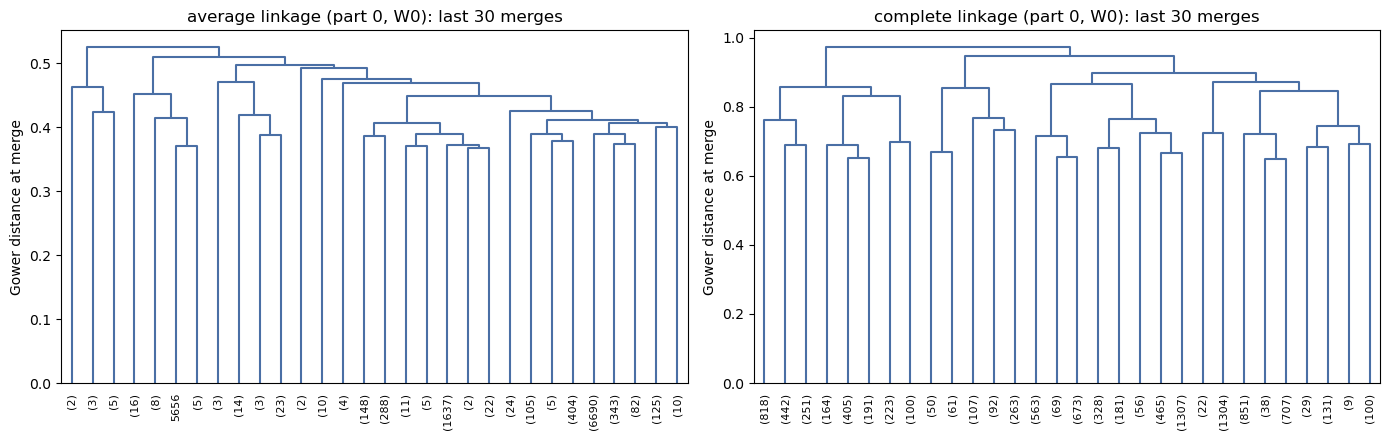

In [17]:
# Top of each dendrogram (last 30 merges). Leaf labels in brackets are the number of children below that branch.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (method, Z) in zip(axes, Z0.items()):
    dendrogram(Z, truncate_mode="lastp", p=30, show_leaf_counts=True, leaf_rotation=90,
               leaf_font_size=8, color_threshold=0, above_threshold_color="#4a6fa5", ax=ax)
    ax.set_title(f"{method} linkage (part 0, W0): last 30 merges")
    ax.set_ylabel("Gower distance at merge")
plt.tight_layout()
plt.show()

## 8 · Evaluation for k = 2–10 (part 0, W0)

**What is reported for each linkage and k:**
- **mean silhouette** over the 10,000 children (−1 to 1; higher = children are closer to their own cluster than to the nearest other cluster)
- **per-cluster silhouette** and the share of each cluster's children with a negative silhouette
- cluster sizes, the smallest cluster, the share of the largest cluster, the number of clusters under 1% of the sample (fewer than 100 children), and singletons

**How these results are used (approved rules):**
- Clusters under 1% are **flagged and investigated, not discarded**. The investigation below lists which feature values the members of each small cluster share.
- A 0.02 difference in mean silhouette is a **practical guideline** for "noticeably different", not a statistical threshold.
- No k is chosen here. The choice (Section 11) weighs stability, silhouette, sizes, interpretability and simplicity together, and needs the user's approval.

**Implementation notes:** the square float32 distance matrix is built once and reused for every k and both linkages; the condensed vector is then deleted to free memory. scikit-learn gives a singleton cluster a silhouette of 0.

In [18]:
def evaluate_labels(D_sq, Z_by_method, k_range=K_RANGE, **tags):
    # Cut each tree at every k; return (summary per linkage x k, per-cluster table, {(linkage, k): labels}).
    n = D_sq.shape[0]
    rows, cluster_rows, labels_by_key = [], [], {}
    for method, Z in Z_by_method.items():
        for k in k_range:
            labels = fcluster(Z, t=k, criterion="maxclust")
            sizes = np.bincount(labels)[1:]
            s = silhouette_samples(D_sq, labels, metric="precomputed")
            labels_by_key[(method, k)] = labels
            rows.append({**tags, "linkage": method, "k_requested": k, "k_obtained": len(sizes),
                         "mean_silhouette": s.mean(), "smallest_cluster": int(sizes.min()),
                         "largest_cluster_share": sizes.max() / n,
                         "clusters_below_1pct": int((sizes < MIN_CLUSTER_SHARE * n).sum()),
                         "singletons": int((sizes == 1).sum()),
                         "sizes": " ".join(map(str, sorted(sizes, reverse=True)))})
            for c, size in enumerate(sizes, start=1):
                sc = s[labels == c]
                cluster_rows.append({**tags, "linkage": method, "k": k, "cluster": c, "size": int(size),
                                     "share": size / n, "mean_silhouette": sc.mean(),
                                     "share_negative_silhouette": (sc < 0).mean(),
                                     "below_1pct": bool(size < MIN_CLUSTER_SHARE * n)})
    return pd.DataFrame(rows), pd.DataFrame(cluster_rows), labels_by_key


with monitor("square float32", n=SAMPLE_SIZE, part=0):
    D0_sq = condensed_to_square_float32(d0)
del d0
gc.collect()

with monitor("silhouette k=2..10 x 2 linkages", n=SAMPLE_SIZE, part=0):
    eval_w0, percl_w0, labels_w0 = evaluate_labels(D0_sq, Z0, part=0, weighting="W0")

assert (eval_w0["k_obtained"] == eval_w0["k_requested"]).all(), "a cut produced fewer clusters than requested"
display(eval_w0.round(3))

,part,weighting,linkage,k_requested,k_obtained,mean_silhouette,smallest_cluster,largest_cluster_share,clusters_below_1pct,singletons,sizes
0,0,W0,average,2,2,0.286,10,0.999,1,0,9990 10
1,0,W0,average,3,3,0.231,10,0.996,2,0,9960 30 10
2,0,W0,average,4,4,0.191,10,0.992,3,0,9917 43 30 10
3,0,W0,average,5,5,0.136,2,0.992,4,0,9915 43 30 10 2
4,0,W0,average,6,6,0.111,2,0.990,5,0,9905 43 30 10 10 2
5,0,W0,average,7,7,0.104,2,0.990,6,0,9905 40 30 10 10 3 2
6,0,W0,average,8,8,0.079,2,0.990,7,0,9901 40 30 10 10 4 3 2
7,0,W0,average,9,9,0.057,2,0.990,8,0,9901 40 30 10 8 4 3 2 2
8,0,W0,average,10,10,0.046,2,0.990,9,0,9901 40 16 14 10 8 4 3 2 2
9,0,W0,complete,2,2,0.199,2594,0.741,0,0,7406 2594


In [19]:
# Mean silhouette and size diagnostics side by side
display(eval_w0.pivot(index="k_requested", columns="linkage",
                      values=["mean_silhouette", "smallest_cluster", "largest_cluster_share", "clusters_below_1pct"])
        .round(3))

# Per-cluster silhouette (one row per cluster; shown here for k = 2-6, the full table is kept in percl_w0)
display(percl_w0[percl_w0["k"] <= 6].round(3).set_index(["linkage", "k", "cluster"]))

mean_silhouette          smallest_cluster           \
linkage             average complete          average complete   
k_requested                                                      
2                     0.286    0.199             10.0   2594.0   
3                     0.231    0.208             10.0    573.0   
4                     0.191    0.122             10.0    573.0   
5                     0.136    0.092              2.0    573.0   
6                     0.111    0.115              2.0    573.0   
7                     0.104    0.098              2.0    573.0   
8                     0.079    0.098              2.0    111.0   
9                     0.057    0.104              2.0    111.0   
10                    0.046    0.112              2.0    111.0   

            largest_cluster_share          clusters_below_1pct           
linkage                   average complete             average complete  
k_requested                                                              
2                           0.999    0.741                 1.0      0.0  
3                           0.996    0.683                 2.0      0.0  
4                           0.992    0.364                 3.0      0.0  
5                           0.992    0.364                 4.0      0.0  
6                           0.990    0.259                 5.0      0.0  
7                           0.990    0.234                 6.0      0.0  
8                           0.990    0.234                 7.0      0.0  
9                           0.990    0.234                 8.0      0.0  
10                          0.990    0.234                 9.0      0.0

part weighting  size  share  mean_silhouette  \
linkage  k cluster                                                 
average  2 1           0        W0    10  0.001            0.275   
           2           0        W0  9990  0.999            0.286   
         3 1           0        W0    10  0.001            0.242   
           2           0        W0    30  0.003            0.219   
           3           0        W0  9960  0.996            0.231   
         4 1           0        W0    10  0.001            0.227   
           2           0        W0    30  0.003            0.205   
           3           0        W0    43  0.004            0.226   
           4           0        W0  9917  0.992            0.191   
         5 1           0        W0    10  0.001            0.227   
           2           0        W0    30  0.003            0.195   
           3           0        W0    43  0.004            0.184   
           4           0        W0     2  0.000            0.563   
           5           0        W0  9915  0.992            0.135   
         6 1           0        W0    10  0.001            0.225   
           2           0        W0    30  0.003            0.195   
           3           0        W0    43  0.004            0.158   
           4           0        W0     2  0.000            0.550   
           5           0        W0    10  0.001            0.333   
           6           0        W0  9905  0.990            0.110   
complete 2 1           0        W0  2594  0.259            0.243   
           2           0        W0  7406  0.741            0.183   
         3 1           0        W0  2594  0.259            0.179   
           2           0        W0   573  0.057            0.064   
           3           0        W0  6833  0.683            0.231   
         4 1           0        W0  2594  0.259            0.137   
           2           0        W0   573  0.057            0.053   
           3           0        W0  3642  0.364            0.119   
           4           0        W0  3191  0.319            0.125   
         5 1           0        W0  2594  0.259            0.097   
           2           0        W0   573  0.057            0.036   
           3           0        W0  3642  0.364           -0.020   
           4           0        W0  1326  0.133            0.419   
           5           0        W0  1865  0.186            0.087   
         6 1           0        W0  2594  0.259            0.083   
           2           0        W0   573  0.057            0.032   
           3           0        W0  1305  0.130            0.028   
           4           0        W0  2337  0.234            0.105   
           5           0        W0  1326  0.133            0.400   
           6           0        W0  1865  0.186            0.056   

                    share_negative_silhouette  below_1pct  
linkage  k cluster                                         
average  2 1                            0.000        True  
           2                            0.063       False  
         3 1                            0.000        True  
           2                            0.033        True  
           3                            0.113       False  
         4 1                            0.000        True  
           2                            0.067        True  
           3                            0.023        True  
           4                            0.141       False  
         5 1                            0.000        True  
           2                            0.067        True  
           3                            0.023        True  
           4                            0.000        True  
           5                            0.227       False  
         6 1                            0.000        True  
           2                            0.067        True  
           3                            0.070        True  
           4           

In [20]:
# ---- Investigate clusters under 1% (flag, do not discard) ----------------------------------------
# Hierarchical clusters are nested, so the same small group usually appears at many k. Each distinct
# group is listed once, at the smallest k where it first appears as a separate cluster.
FEATURE_LABELS = dict(zip(FEATURE_TABLE["feature"], FEATURE_TABLE["description"]))


def small_cluster_catalogue(labels_by_key, data, spec, n, min_shared=0.9, max_base=0.5):
    seen = {}
    for (method, k), labels in sorted(labels_by_key.items(), key=lambda kv: (kv[0][0], kv[0][1])):
        sizes = np.bincount(labels)
        for c in range(1, len(sizes)):
            if 0 < sizes[c] < MIN_CLUSTER_SHARE * n:
                members = np.flatnonzero(labels == c)
                key = (method, members.tobytes())
                if key not in seen:
                    seen[key] = {"linkage": method, "first_k": k, "size": len(members), "members": members}
    rows = []
    for item in seen.values():
        sub = data.iloc[item["members"]]
        shared = []
        for f in spec["feature"]:
            vc = sub[f].value_counts(normalize=True, dropna=False)
            top_val, top_share = vc.index[0], vc.iloc[0]
            base = data[f].isna().mean() if pd.isna(top_val) else (data[f] == top_val).mean()
            if top_share >= min_shared and base < max_base:      # shared by members AND uncommon in the sample
                shared.append(f"{f}={top_val:g} ({top_share:.0%} of members vs {base:.0%} of sample)")
        rows.append({"linkage": item["linkage"], "first_k": item["first_k"], "size": item["size"],
                     "mean age": round(sub["sc_age_years"].mean(), 1),
                     "distinctive shared values": "; ".join(shared) or "(no uncommon value shared by >= 90%)"})
    return pd.DataFrame(rows)


small_w0 = small_cluster_catalogue(labels_w0, sample0, SPEC_PRIMARY, SAMPLE_SIZE)
print(f"Distinct clusters under 1% across k = 2-10: "
      + ", ".join(f"{m}: {int((small_w0['linkage'] == m).sum())}" for m in LINKAGE_METHODS))
with pd.option_context("display.max_colwidth", None):
    display(small_w0)
print("Codes: blindness/k4q23 1 = yes; k4q22_r 1 = received treatment, 2 = needed but not received; "
      "foodsit 3-4 = sometimes/often not enough to eat; higrade 1 = less than high school; "
      "k10q1x 2 = amenity not in neighborhood.")

Distinct clusters under 1% across k = 2-10: average: 12, complete: 0


,linkage,first_k,size,mean age,distinctive shared values
0,average,2,10,11.0,sc_sex=2 (90% of members vs 49% of sample); k10q13=1 (100% of members vs 47% of sample)
1,average,3,30,12.2,k10q12=2 (100% of members vs 23% of sample)
2,average,4,43,12.9,k4q22_r=2 (98% of members vs 3% of sample)
3,average,5,2,1.0,sc_age_years=1 (100% of members vs 4% of sample); family_r=7 (100% of members vs 3% of sample); sleep_below_minimum=1 (100% of members vs 31% of sample); k10q14=2 (100% of members vs 32% of sample)
4,average,6,10,12.8,blindness=1 (100% of members vs 1% of sample)
5,average,7,3,9.7,sc_sex=2 (100% of members vs 49% of sample); family_r=6 (100% of members vs 5% of sample); k4q22_r=2 (100% of members vs 3% of sample); k10q12=2 (100% of members vs 23% of sample); k10q14=2 (100% of members vs 32% of sample)
6,average,7,40,13.1,k4q22_r=2 (98% of members vs 3% of sample)
7,average,8,4,11.8,k4q22_r=1 (100% of members vs 14% of sample)
8,average,9,2,4.0,family_r=7 (100% of members vs 3% of sample); k4q22_r=2 (100% of members vs 3% of sample); foodsit=3 (100% of members vs 3% of sample); k10q13=1 (100% of members vs 47% of sample)
9,average,9,8,12.8,sc_sex=2 (100% of members vs 49% of sample); k10q13=1 (100% of members vs 47% of sample)


Codes: blindness/k4q23 1 = yes; k4q22_r 1 = received treatment, 2 = needed but not received; foodsit 3-4 = sometimes/often not enough to eat; higrade 1 = less than high school; k10q1x 2 = amenity not in neighborhood.


## 9 · Sensitivity: domain-balanced weights (W1)

**What:** repeat Sections 7–8 on the **same 10,000 children** with W1 weights (each domain has a total weight of 1: general, health and lifestyle features 1/3 each; environment features 1/5 each).

**Why:** under W0 the environment domain has 5 of the 14 features, so it carries more weight than the others. W1 checks whether the clusters depend on that.

**How W0 and W1 are compared:**
- Silhouettes computed under different distance definitions are **not directly comparable**. So each solution is also **cross-evaluated**: W1 clusters scored on W0 distances, and W0 clusters scored on W1 distances.
- **ARI on the sample** (same 10,000 children) measures how similar the two partitions are: 1 = identical, about 0 = no more similar than chance.
- The decisive comparison is the **full-data ARI** between W0 and W1 against the **stability band** of Section 10. W2 (neighborhood items at 1/3 each) is run only if W1 differs by more than that band, and only after the Section 11 checkpoint.

In [21]:
SPEC_W1 = build_spec("primary", "W1")
X0_w1 = encode(sample0, SPEC_W1)
assert np.array_equal(X0_w1, X0, equal_nan=True)          # same features; only the weights differ

with monitor("gower_condensed W1", n=SAMPLE_SIZE, part=0):
    d1 = gower_condensed(X0_w1, SPEC_W1)
assert np.isfinite(d1).all() and d1.min() >= 0 and d1.max() <= 1

Z1, coph1 = {}, {}
for method in LINKAGE_METHODS:
    require_memory(d1.nbytes, label=f"linkage {method} W1 (internal copy)")
    with monitor(f"linkage {method} W1", n=SAMPLE_SIZE, part=0):
        Z1[method] = linkage(d1, method=method)
    assert is_valid_linkage(Z1[method]) and is_monotonic(Z1[method])
    coph1[method] = cophenetic_correlation(Z1[method], d1)
    print(f"OK  {method:8s} W1 linkage valid and monotonic | cophenetic correlation {coph1[method]:.3f}")

with monitor("square float32 W1", n=SAMPLE_SIZE, part=0):
    D1_sq = condensed_to_square_float32(d1)
del d1
gc.collect()

with monitor("silhouette W1", n=SAMPLE_SIZE, part=0):
    eval_w1, percl_w1, labels_w1 = evaluate_labels(D1_sq, Z1, part=0, weighting="W1")
display(eval_w1.round(3))

OK  average  W1 linkage valid and monotonic | cophenetic correlation 0.647


OK  complete W1 linkage valid and monotonic | cophenetic correlation 0.493


,part,weighting,linkage,k_requested,k_obtained,mean_silhouette,smallest_cluster,largest_cluster_share,clusters_below_1pct,singletons,sizes
0,0,W1,average,2,2,0.342,2,1.000,1,0,9998 2
1,0,W1,average,3,3,0.264,2,0.998,2,0,9984 14 2
2,0,W1,average,4,4,0.205,1,0.998,3,1,9984 13 2 1
3,0,W1,average,5,5,0.159,1,0.996,4,1,9955 29 13 2 1
4,0,W1,average,6,6,0.126,1,0.989,5,1,9889 66 29 13 2 1
5,0,W1,average,7,7,0.122,1,0.989,6,2,9889 65 29 13 2 1 1
6,0,W1,average,8,8,0.115,1,0.970,6,2,9696 193 65 29 13 2 1 1
7,0,W1,average,9,9,0.108,1,0.970,7,2,9696 193 62 29 13 3 2 1 1
8,0,W1,average,10,10,0.159,1,0.807,7,2,8073 1623 193 62 29 13 3 2 1 1
9,0,W1,complete,2,2,0.183,2351,0.765,0,0,7649 2351


In [22]:
# Cross-evaluation and sample-level agreement between W0 and W1
cross_rows = []
with monitor("W0/W1 cross-evaluation", n=SAMPLE_SIZE, part=0):
    for method in LINKAGE_METHODS:
        for k in K_RANGE:
            a, b = labels_w0[(method, k)], labels_w1[(method, k)]
            cross_rows.append({
                "linkage": method, "k": k,
                "W0 clusters on W0 distances": eval_w0.set_index(["linkage", "k_requested"]).loc[(method, k), "mean_silhouette"],
                "W1 clusters on W0 distances": silhouette_samples(D0_sq, b, metric="precomputed").mean(),
                "W1 clusters on W1 distances": eval_w1.set_index(["linkage", "k_requested"]).loc[(method, k), "mean_silhouette"],
                "W0 clusters on W1 distances": silhouette_samples(D1_sq, a, metric="precomputed").mean(),
                "ARI W0 vs W1 (sample)": adjusted_rand_score(a, b),
            })
cross_w0_w1 = pd.DataFrame(cross_rows)
display(cross_w0_w1.round(3).set_index(["linkage", "k"]))

small_w1 = small_cluster_catalogue(labels_w1, sample0, SPEC_W1, SAMPLE_SIZE)
print(f"W1 distinct clusters under 1% across k = 2-10: "
      + ", ".join(f"{m}: {int((small_w1['linkage'] == m).sum())}" for m in LINKAGE_METHODS))

del D0_sq, D1_sq
_ = gc.collect()

W0 clusters on W0 distances  W1 clusters on W0 distances  \
linkage  k                                                              
average  2                         0.286                        0.330   
         3                         0.231                        0.251   
         4                         0.191                        0.178   
         5                         0.136                        0.144   
         6                         0.111                        0.109   
         7                         0.104                        0.106   
         8                         0.079                        0.090   
         9                         0.057                        0.084   
         10                        0.046                        0.126   
complete 2                         0.199                        0.166   
         3                         0.208                        0.148   
         4                         0.122                        0.132   
         5                         0.092                        0.140   
         6                         0.115                        0.139   
         7                         0.098                        0.140   
         8                         0.098                        0.134   
         9                         0.104                        0.137   
         10                        0.112                        0.140   

             W1 clusters on W1 distances  W0 clusters on W1 distances  \
linkage  k                                                              
average  2                         0.342                        0.295   
         3                         0.264                        0.239   
         4                         0.205                        0.208   
         5                         0.159                        0.140   
         6                         0.126                        0.113   
         7                         0.122                        0.110   
         8                         0.115                        0.080   
         9                         0.108                        0.061   
         10                        0.159                        0.052   
complete 2                         0.183                        0.142   
         3                         0.166                        0.153   
         4                         0.158                        0.110   
         5                         0.166                        0.083   
         6                         0.161                        0.096   
         7                         0.163                        0.086   
         8                         0.159                        0.085   
         9                         0.162                        0.089   
         10                        0.160                        0.096   

             ARI W0 vs W1 (sample)  
linkage  k                          
average  2                  -0.000  
         3                   0.176  
         4                   0.199  
         5                   0.148  
         6                   0.175  
         7                   0.175  
         8                   0.267  
         9                   0.267  
         10                  0.064  
complete 2                  -0.019  
         3                   0.052  
         4                   0.098  
         5                   0.130  
         6                   0.236  
         7                   0.237  
         8                   0.237  
         9                   0.251  
         10                  0.258

W1 distinct clusters under 1% across k = 2-10: average: 10, complete: 1


## 10 · Stability across the five replicate samples

**What:**
1. Cluster each of parts 1–4 exactly as part 0 was clustered (W0, both linkages, k = 2–10), and record their silhouettes and sizes.
2. Build a **full-data labelling** from each part: its 10,000 children keep their hierarchical labels, and the other 41,375 children are assigned to the cluster with the smallest average Gower distance (the approved assignment rule from Section 3).
3. For each linkage and k, compare the five full-data labellings pairwise (10 pairs) with the **Adjusted Rand Index (ARI)**.

**Why full-data labellings:** the five parts contain different children, so their partitions can only be compared on a common set of children. Assigning everyone gives that common set (all 51,375).

**Reading the results:**
- ARI near 1: the same grouping is found from different samples (stable); near 0: no better than chance.
- The **stability band** (min–max of the 10 ARIs) is the reference for every sensitivity comparison: a sensitivity run that agrees with the primary model about as well as two replicate samples agree with each other has not changed the result materially.
- **Matched agreement:** cluster labels are arbitrary, so each pair of labellings is first matched with the Hungarian method (maximum overlap), then the share of children in matched clusters is reported. It is easier to read than ARI and is used later to compare profiles across parts.

**Caveat:** the five parts are disjoint stratified replicate samples from one dataset, not independent samples from the population.

In [23]:
def full_data_labels(sample_idx, X_sample, labels_by_key, spec):
    # Sample children keep their hierarchical labels; every other child gets the nearest cluster by average Gower distance.
    in_sample = np.zeros(len(df), dtype=bool)
    in_sample[sample_idx] = True
    out_idx = np.flatnonzero(~in_sample)
    D_by_key = mean_distance_to_clusters(encode(df.iloc[out_idx], spec), X_sample, labels_by_key, spec)
    full = {}
    for key, labels in labels_by_key.items():
        lab = np.empty(len(df), dtype=np.int64)
        lab[sample_idx] = labels
        lab[out_idx] = assign_from_distances(*D_by_key[key])["cluster"].to_numpy()
        full[key] = lab
    return full


def matched_agreement(a, b):
    # Share of children in matched clusters after optimal one-to-one matching of labels (Hungarian method).
    ca, ia = np.unique(a, return_inverse=True)
    cb, ib = np.unique(b, return_inverse=True)
    table = np.zeros((len(ca), len(cb)), dtype=np.int64)
    np.add.at(table, (ia, ib), 1)
    r, c = linear_sum_assignment(-table)
    return table[r, c].sum() / len(a)


with monitor("full-data labels part 0 W0", n=SAMPLE_SIZE, part=0):
    full_labels = {0: full_data_labels(sample0_idx, X0, labels_w0, SPEC_PRIMARY)}
with monitor("full-data labels part 0 W1", n=SAMPLE_SIZE, part=0):
    full_labels_w1 = full_data_labels(sample0_idx, X0_w1, labels_w1, SPEC_W1)
print("OK  full-data labellings for part 0 (W0 and W1)")

OK  full-data labellings for part 0 (W0 and W1)


In [24]:
# Parts 1-4: same pipeline as part 0 (W0). Takes several minutes per part.
rep_evals, rep_coph = [eval_w0], [{"part": 0, **coph0}]
for p in range(1, N_PARTS):
    idx = parts[p]
    X_p = encode(df.iloc[idx], SPEC_PRIMARY)
    with monitor("gower_condensed W0", n=SAMPLE_SIZE, part=p):
        d_p = gower_condensed(X_p, SPEC_PRIMARY)
    Z_p, coph_p = {}, {"part": p}
    for method in LINKAGE_METHODS:
        require_memory(d_p.nbytes, label=f"linkage {method} part {p}")
        with monitor(f"linkage {method}", n=SAMPLE_SIZE, part=p):
            Z_p[method] = linkage(d_p, method=method)
        assert is_valid_linkage(Z_p[method]) and is_monotonic(Z_p[method])
        coph_p[method] = cophenetic_correlation(Z_p[method], d_p)
    with monitor("square float32", n=SAMPLE_SIZE, part=p):
        D_sq_p = condensed_to_square_float32(d_p)
    del d_p
    with monitor("silhouette k=2..10 x 2 linkages", n=SAMPLE_SIZE, part=p):
        ev_p, _, labels_p = evaluate_labels(D_sq_p, Z_p, part=p, weighting="W0")
    del D_sq_p
    gc.collect()
    with monitor("full-data labels", n=SAMPLE_SIZE, part=p):
        full_labels[p] = full_data_labels(idx, X_p, labels_p, SPEC_PRIMARY)
    rep_evals.append(ev_p)
    rep_coph.append(coph_p)
    print(f"OK  part {p} done | available RAM {available_mib():,.0f} MiB")

rep_eval = pd.concat(rep_evals, ignore_index=True)
display(pd.DataFrame(rep_coph).set_index("part").round(3).rename(columns=lambda c: f"cophenetic {c}"))

OK  part 1 done | available RAM 5,155 MiB


OK  part 2 done | available RAM 5,095 MiB


OK  part 3 done | available RAM 5,005 MiB


OK  part 4 done | available RAM 4,775 MiB


,cophenetic average,cophenetic complete
part,,
0,0.638,0.482
1,0.641,0.511
2,0.633,0.530
3,0.632,0.425
4,0.633,0.486


In [25]:
# Do the replicate samples show the same silhouette and size pattern as part 0?
rep_summary = rep_eval.groupby(["linkage", "k_requested"]).agg(
    silhouette_part0=("mean_silhouette", "first"),
    silhouette_min=("mean_silhouette", "min"),
    silhouette_max=("mean_silhouette", "max"),
    smallest_cluster_min=("smallest_cluster", "min"),
    parts_with_cluster_below_1pct=("clusters_below_1pct", lambda s: int((s > 0).sum())),
)
display(rep_summary.round(3))

# Pairwise stability of the full-data labellings (10 pairs per linkage and k)
stab_rows = []
for method in LINKAGE_METHODS:
    for k in K_RANGE:
        for p, q in combinations(range(N_PARTS), 2):
            a, b = full_labels[p][(method, k)], full_labels[q][(method, k)]
            stab_rows.append({"linkage": method, "k": k, "part_a": p, "part_b": q,
                              "ari": adjusted_rand_score(a, b), "matched_agreement": matched_agreement(a, b)})
stability = pd.DataFrame(stab_rows)
band = stability.groupby(["linkage", "k"]).agg(
    ari_min=("ari", "min"), ari_mean=("ari", "mean"), ari_max=("ari", "max"),
    matched_agreement_mean=("matched_agreement", "mean"), matched_agreement_min=("matched_agreement", "min"))
display(band.round(3))

silhouette_part0  silhouette_min  silhouette_max  \
linkage  k_requested                                                     
average  2                       0.286           0.250           0.303   
         3                       0.231           0.171           0.243   
         4                       0.191           0.122           0.191   
         5                       0.136           0.117           0.152   
         6                       0.111           0.076           0.145   
         7                       0.104           0.069           0.191   
         8                       0.079           0.060           0.179   
         9                       0.057           0.015           0.179   
         10                      0.046          -0.004           0.170   
complete 2                       0.199           0.089           0.212   
         3                       0.208           0.099           0.208   
         4                       0.122           0.073           0.171   
         5                       0.092           0.079           0.170   
         6                       0.115           0.080           0.157   
         7                       0.098           0.098           0.155   
         8                       0.098           0.098           0.160   
         9                       0.104           0.104           0.141   
         10                      0.112           0.108           0.155   

                      smallest_cluster_min  parts_with_cluster_below_1pct  
linkage  k_requested                                                       
average  2                               5                              4  
         3                               5                              5  
         4                               2                              5  
         5                               2                              5  
         6                               2                              5  
         7                               2                              5  
         8                               1                              5  
         9                               1                              5  
         10                              1                              5  
complete 2                            2297                              0  
         3                             271                              0  
         4                             271                              0  
         5                             151                              0  
         6                             151                              0  
         7                             151                              0  
         8                             111                              0  
         9                             111                              0  
         10                             64                              1

ari_min  ari_mean  ari_max  matched_agreement_mean  \
linkage  k                                                        
average  2     0.055     0.213    0.352                   0.913   
         3     0.162     0.265    0.402                   0.842   
         4     0.267     0.355    0.421                   0.802   
         5     0.289     0.340    0.403                   0.755   
         6     0.277     0.319    0.380                   0.713   
         7     0.168     0.276    0.380                   0.644   
         8     0.174     0.278    0.349                   0.623   
         9     0.205     0.339    0.641                   0.621   
         10    0.211     0.342    0.636                   0.604   
complete 2     0.263     0.558    0.760                   0.865   
         3     0.302     0.525    0.805                   0.748   
         4     0.286     0.350    0.510                   0.594   
         5     0.217     0.319    0.424                   0.545   
         6     0.193     0.334    0.516                   0.531   
         7     0.189     0.338    0.530                   0.504   
         8     0.198     0.351    0.543                   0.516   
         9     0.259     0.397    0.630                   0.538   
         10    0.260     0.383    0.609                   0.524   

             matched_agreement_min  
linkage  k                          
average  2                   0.899  
         3                   0.810  
         4                   0.749  
         5                   0.730  
         6                   0.679  
         7                   0.550  
         8                   0.536  
         9                   0.545  
         10                  0.532  
complete 2                   0.757  
         3                   0.554  
         4                   0.540  
         5                   0.426  
         6                   0.404  
         7                   0.353  
         8                   0.367  
         9                   0.435  
         10                  0.410

In [26]:
# W1 vs W0 on the full data, judged against the stability band
w1_rows = []
for method in LINKAGE_METHODS:
    for k in K_RANGE:
        a, b = full_labels[0][(method, k)], full_labels_w1[(method, k)]
        lo, hi = band.loc[(method, k), ["ari_min", "ari_max"]]
        ari = adjusted_rand_score(a, b)
        w1_rows.append({"linkage": method, "k": k, "ARI W0 vs W1 (full data)": ari,
                        "matched agreement W0 vs W1": matched_agreement(a, b),
                        "stability band min": lo, "stability band max": hi,
                        "W1 differs more than the band": bool(ari < lo)})
w1_vs_band = pd.DataFrame(w1_rows).set_index(["linkage", "k"])
display(w1_vs_band.round(3))
print("If W1 falls below the band for the candidate linkage and k, the approved plan adds a W2 run "
      "(decided at the Section 11 checkpoint).")

ARI W0 vs W1 (full data)  matched agreement W0 vs W1  \
linkage  k                                                          
average  2                      0.035                       0.915   
         3                      0.432                       0.900   
         4                      0.537                       0.873   
         5                      0.483                       0.810   
         6                      0.480                       0.761   
         7                      0.498                       0.748   
         8                      0.492                       0.729   
         9                      0.462                       0.693   
         10                     0.464                       0.680   
complete 2                      0.011                       0.604   
         3                      0.082                       0.558   
         4                      0.184                       0.520   
         5                      0.077                       0.363   
         6                      0.391                       0.606   
         7                      0.396                       0.591   
         8                      0.381                       0.581   
         9                      0.356                       0.541   
         10                     0.323                       0.471   

             stability band min  stability band max  \
linkage  k                                            
average  2                0.055               0.352   
         3                0.162               0.402   
         4                0.267               0.421   
         5                0.289               0.403   
         6                0.277               0.380   
         7                0.168               0.380   
         8                0.174               0.349   
         9                0.205               0.641   
         10               0.211               0.636   
complete 2                0.263               0.760   
         3                0.302               0.805   
         4                0.286               0.510   
         5                0.217               0.424   
         6                0.193               0.516   
         7                0.189               0.530   
         8                0.198               0.543   
         9                0.259               0.630   
         10               0.260               0.609   

             W1 differs more than the band  
linkage  k                                  
average  2                            True  
         3                           False  
         4                           False  
         5                           False  
         6                           False  
         7                           False  
         8                           False  
         9                           False  
         10                          False  
complete 2                            True  
         3                            True  
         4                            True  
         5                            True  
         6                           False  
         7                           False  
         8                           False  
         9                           False  
         10                          False

If W1 falls below the band for the candidate linkage and k, the approved plan adds a W2 run (decided at the Section 11 checkpoint).


## 11 · ⛔ CHECKPOINT: evidence for choosing the linkage, weighting and k

The table below brings together, for each linkage and k (part 0, W0 unless stated):
- **cophenetic correlation** of the tree (same for every k)
- **mean silhouette**, the **smallest cluster**, the **largest cluster's share**, and the number of **clusters under 1%**
- the range of mean silhouettes across the five replicate parts
- **stability**: mean and minimum pairwise ARI across the five parts
- **W1 sensitivity**: full-data ARI between W0 and W1, and whether it falls below the stability band

**No selection is made in this notebook.** The recommendation and the user's decision are recorded here after review, and Sections 12+ (assignment validation, remaining sensitivity runs, profiles and exports) use only the approved settings.

In [27]:
evidence = (eval_w0.rename(columns={"k_requested": "k"})
            .set_index(["linkage", "k"])[["mean_silhouette", "smallest_cluster", "largest_cluster_share",
                                          "clusters_below_1pct", "sizes"]]
            .join(rep_summary.rename_axis(["linkage", "k"])[["silhouette_min", "silhouette_max",
                                                             "parts_with_cluster_below_1pct"]])
            .join(band[["ari_mean", "ari_min", "matched_agreement_mean"]])
            .join(w1_vs_band[["ARI W0 vs W1 (full data)", "W1 differs more than the band"]]))
evidence.insert(0, "cophenetic", [coph0[m] for m in evidence.index.get_level_values("linkage")])
with pd.option_context("display.max_colwidth", None, "display.width", 250):
    display(evidence.round(3))

perf = pd.DataFrame(PERF_LOG)
print(f"Total monitored time: {perf['seconds'].sum() / 60:.1f} min | "
      f"process peak working set: {PROC.memory_info().peak_wset / 2**20:,.0f} MiB")
display(perf[perf.get("part").notna()] if "part" in perf else perf)

cophenetic  mean_silhouette  smallest_cluster  largest_cluster_share  clusters_below_1pct                                         sizes  silhouette_min  silhouette_max  parts_with_cluster_below_1pct  ari_mean  ari_min  \
linkage  k                                                                                                                                                                                                                               
average  2        0.638            0.286                10                  0.999                    1                                       9990 10           0.250           0.303                              4     0.213    0.055   
         3        0.638            0.231                10                  0.996                    2                                    9960 30 10           0.171           0.243                              5     0.265    0.162   
         4        0.638            0.191                10                  0.992                    3                                 9917 43 30 10           0.122           0.191                              5     0.355    0.267   
         5        0.638            0.136                 2                  0.992                    4                               9915 43 30 10 2           0.117           0.152                              5     0.340    0.289   
         6        0.638            0.111                 2                  0.990                    5                            9905 43 30 10 10 2           0.076           0.145                              5     0.319    0.277   
         7        0.638            0.104                 2                  0.990                    6                          9905 40 30 10 10 3 2           0.069           0.191                              5     0.276    0.168   
         8        0.638            0.079                 2                  0.990                    7                        9901 40 30 10 10 4 3 2           0.060           0.179                              5     0.278    0.174   
         9        0.638            0.057                 2                  0.990                    8                       9901 40 30 10 8 4 3 2 2           0.015           0.179                              5     0.339    0.205   
         10       0.638            0.046                 2                  0.990                    9                    9901 40 16 14 10 8 4 3 2 2          -0.004           0.170                              5     0.342    0.211   
complete 2        0.482            0.199              2594                  0.741                    0                                     7406 2594           0.089           0.212                              0     0.558    0.263   
         3        0.482            0.208               573                  0.683                    0                                 6833 2594 573           0.099           0.208                              0     0.525    0.302   
         4        0.482            0.122               573                  0.364                    0                            3642 3191 2594 573           0.073           0.171                              0     0.350    0.286   
         5        0.482            0.092               573                  0.364                    0                       3642 2594 1865 1326 573           0.079           0.170                              0     0.319    0.217   
         6        0.482            0.115               573                  0.259                    0                  2594 2337 1865 1326 1305 573           0.080           0.157                              0     0.334    0.193   
         7        0.482            0.098               573                  0.234                    0             2337 1865 1511 1326 1305 1083 573           0.098           0.155                              0     0.338    0.189   
         8        0.482            

Total monitored time: 11.1 min | process peak working set: 1,519 MiB


,step,n,seconds,peak_alloc_mib,rss_before_mib,rss_after_mib,available_after_mib,part
9,gower_condensed W0,10000,9.374,605.5,247.1,630.5,4349.0,0.0
10,linkage average,10000,1.805,47.7,630.5,630.5,4368.0,0.0
11,cophenetic average,10000,0.994,495.9,631.2,631.1,4359.0,0.0
12,linkage complete,10000,1.812,47.8,631.1,631.1,4365.0,0.0
13,cophenetic complete,10000,1.023,495.9,631.1,631.6,4328.0,0.0
14,square float32,10000,0.392,381.5,636.7,1018.1,3966.0,0.0
15,silhouette k=2..10 x 2 linkages,10000,13.404,3.7,636.7,640.1,4332.0,0.0
16,gower_condensed W1,10000,9.449,605.3,641.3,1023.3,3999.0,0.0
17,linkage average W1,10000,1.750,47.7,1023.2,1023.2,4006.0,0.0
18,linkage complete W1,10000,1.678,47.8,1023.3,1023.3,4018.0,0.0


### Decision record (2026-11-10)

Decisions made by the user at this checkpoint, after reviewing the evidence above:

| Decision | Outcome |
|---|---|
| Linkage | **Complete linkage approved.** Average linkage is not used: it is degenerate at n = 10,000 in all five replicate samples (one cluster holds 99% or more of the children). The user also asked for a further discussion of the cluster sizes, which is still open. |
| Weighting and k | **W0 (equal weights) and k = 3 approved** as the primary model. |
| W2 definition | The user was unsure. **Working definition (assumption, not a final decision):** the three neighborhood items (`k10q12`, `k10q13`, `k10q14`) together carry the weight of one feature, i.e. 1/3 each; all other features keep weight 1. |
| Amenity items | The user asked to **try** replacing the three neighborhood items with one ordinal count (0–3). It is run below **as a sensitivity run only**. The primary model is unchanged unless the user decides otherwise after seeing the result. |

**Primary model from here on:** part 0 (10,000 children), 14 features, W0, complete linkage, k = 3.
Cluster numbers are re-ordered by size (1 = largest) so they are stable and readable.

## 12 · Primary model: assignment of the remaining children

**What:** the 10,000 sample children keep their hierarchical labels (complete linkage, W0, k = 3). Each of the other 41,375 children is assigned to the cluster with the smallest **average Gower distance** to that cluster's sample members, and the margin to the second-closest cluster is recorded.

**Checks:**
- **Margin distribution:** a small margin means the child is almost as close to a second cluster. Shares below 0.005, 0.01 and 0.02 (Gower units) are reported. Small margins flag ambiguous children; they are **not** removed.
- **Leave-one-out consistency:** each sample child is re-assigned by the same rule using the other members of its own cluster. The share that returns to its hierarchical cluster shows how closely the assignment rule reproduces the tree.
- **Sample vs assigned:** cluster shares and a few key characteristics for sample children and assigned children are compared. Differences are expected only through the sampling design (the sample is stratified, the remainder is not re-balanced).
- Results always distinguish `hierarchical` (in the 10,000 sample) from `assigned`.

In [28]:
PRIMARY = {"linkage": "complete", "weighting": "W0", "k": 3, "part": 0}
EXPORT_DIR, REPORT_DIR = Path.cwd() / "outputs", Path.cwd() / "reports"

# Relabel so that cluster 1 is the largest, 2 the next, ...
raw = labels_w0[("complete", 3)]
size_order = pd.Series(raw).value_counts().index.tolist()
relabel = {old: new for new, old in enumerate(size_order, start=1)}
lab_s = np.array([relabel[x] for x in raw])
print("fcluster label -> final cluster number:", relabel)
print("Sample sizes:", dict(zip(*np.unique(lab_s, return_counts=True))))

in_sample = np.zeros(len(df), dtype=bool)
in_sample[sample0_idx] = True
out_idx = np.flatnonzero(~in_sample)
assert len(out_idx) == len(df) - SAMPLE_SIZE   # 41,375 at the full size

X_out = encode(df.iloc[out_idx], SPEC_PRIMARY)
with monitor("assignment 41,375 (primary)", n=SAMPLE_SIZE):
    clusters_out, D_out = mean_distance_to_clusters(X_out, X0, {"primary": lab_s}, SPEC_PRIMARY)["primary"]
asg = assign_from_distances(clusters_out, D_out)
assert np.isfinite(D_out).all() and (asg["assignment_margin"] >= 0).all()

final_cluster = np.empty(len(df), dtype=np.int64)
final_cluster[sample0_idx] = lab_s
final_cluster[out_idx] = asg["cluster"].to_numpy()
assert (final_cluster > 0).all()

# Consistency with the Section 10 full-data labelling (same rule, different label order)
assert adjusted_rand_score(final_cluster, full_labels[0][("complete", 3)]) == 1.0
print("OK  final labelling equals the Section 10 full-data labelling (ARI = 1)")

fcluster label -> final cluster number: {3: 1, 1: 2, 2: 3}
Sample sizes: {1: 6833, 2: 2594, 3: 573}


OK  final labelling equals the Section 10 full-data labelling (ARI = 1)


In [29]:
# ---- Assignment margin distribution -----------------------------------------------------------
q = np.quantile(asg["assignment_margin"], [0, .05, .25, .5, .75, .95, 1])
print("Assignment margin quantiles (min, 5%, 25%, 50%, 75%, 95%, max):", np.round(q, 4))
print("Exact ties (flagged, assigned to the lowest label):", int(asg["exact_tie"].sum()))
margin_table = pd.DataFrame({
    "threshold": AMBIGUITY_THRESHOLDS,
    "assigned children below": [int((asg["assignment_margin"] < t).sum()) for t in AMBIGUITY_THRESHOLDS],
    "share of assigned": [(asg["assignment_margin"] < t).mean() for t in AMBIGUITY_THRESHOLDS],
}).round(4)
display(margin_table)
display(asg.groupby("cluster")["assignment_margin"].describe(percentiles=[.05, .5]).round(4))

# ---- Leave-one-out consistency of sample children ----------------------------------------------
cl_in, D_in = mean_distance_to_clusters(X0, X0, {"primary": lab_s}, SPEC_PRIMARY)["primary"]
n_c = np.bincount(lab_s)[1:]                      # cluster sizes, index = cluster - 1
own = lab_s - 1
rows_i = np.arange(len(D_in))
D_loo = D_in.copy()
D_loo[rows_i, own] = D_in[rows_i, own] * n_c[own] / (n_c[own] - 1)   # exclude the child itself (distance 0)
loo = assign_from_distances(cl_in, D_loo)
consistent = loo["cluster"].to_numpy() == lab_s
print(f"\nLeave-one-out: {consistent.mean() * 100:.1f}% of sample children return to their hierarchical cluster")
display(pd.DataFrame({"cluster": cl_in, "sample n": n_c,
                      "% returning to own cluster": [consistent[lab_s == c].mean() * 100 for c in cl_in]}).round(1))
del D_in, D_loo, D_out
_ = gc.collect()

Assignment margin quantiles (min, 5%, 25%, 50%, 75%, 95%, max): [0.     0.0159 0.0591 0.0869 0.1417 0.1522 0.1756]
Exact ties (flagged, assigned to the lowest label): 0


,threshold,assigned children below,share of assigned
0,0.005,776,0.0188
1,0.010,1378,0.0333
2,0.020,2439,0.0589


,count,mean,std,min,5%,50%,max
cluster,,,,,,,
1,26881.0,0.1083,0.0451,0.0,0.0354,0.1369,0.1704
2,11883.0,0.0751,0.0374,0.0,0.0168,0.0767,0.1756
3,2611.0,0.0567,0.0405,0.0,0.0033,0.0489,0.1653



Leave-one-out: 89.2% of sample children return to their hierarchical cluster


,cluster,sample n,% returning to own cluster
0,1,6833,91.6
1,2,2594,87.5
2,3,573,67.7


In [30]:
# ---- Sample vs assigned: cluster shares and key characteristics ------------------------------------
check = df.assign(cluster=final_cluster, group=np.where(in_sample, "hierarchical (sample)", "assigned"))
size_cmp = (pd.crosstab(check["group"], check["cluster"], normalize="index") * 100).round(1)
print("Cluster share (%) within each group:")
display(size_cmp)

key = pd.DataFrame({
    "mean age": check["sc_age_years"],
    "% medication (k4q23)": check["k4q23"].eq(1) * 100.0,
    "% mental-health treatment (k4q22_r = 1)": check["k4q22_r"].eq(1) * 100.0,
    "% screen time 4+ h": check["screentime"].eq(5) * 100.0,
    "% T1 (ages 0-5)": check["formtype"].eq("T1") * 100.0,
})
display(key.groupby([check["cluster"], check["group"]]).mean().round(1))

Cluster share (%) within each group:


cluster,1,2,3
group,,,
assigned,65.0,28.7,6.3
hierarchical (sample),68.3,25.9,5.7


mean age  % medication (k4q23)  \
cluster group                                                   
1       assigned                    9.6                   8.7   
        hierarchical (sample)       9.7                  10.3   
2       assigned                    9.0                   2.4   
        hierarchical (sample)       8.7                   1.9   
3       assigned                   13.3                  64.3   
        hierarchical (sample)      12.8                  52.7   

                               % mental-health treatment (k4q22_r = 1)  \
cluster group                                                            
1       assigned                                                  12.9   
        hierarchical (sample)                                     14.9   
2       assigned                                                   1.6   
        hierarchical (sample)                                      2.4   
3       assigned                                                  82.0   
        hierarchical (sample)                                     60.9   

                               % screen time 4+ h  % T1 (ages 0-5)  
cluster group                                                       
1       assigned                             22.3             27.0  
        hierarchical (sample)                23.3             26.3  
2       assigned                             21.6             32.3  
        hierarchical (sample)                20.4             34.0  
3       assigned                             51.9              1.9  
        hierarchical (sample)                48.9              2.4

## 13 · Sensitivity runs (complete linkage, k = 2–4, part 0 unless stated)

Each run below re-does the full pipeline on part 0 (distances, complete linkage, silhouette) and assigns every other child, giving a **full-data labelling** that is compared with the primary labelling.

| Run | Change from the primary model |
|---|---|
| `W2_neighborhood_third` | The three neighborhood items keep their binary coding but each has weight 1/3 (together one feature's weight). *Working definition; see the decision record.* |
| `amenity_count` | The three neighborhood items are replaced by one ordinal feature: the number of amenities present (0–3). **Requested by the user as an experiment; the primary model is unchanged.** |
| `all_symmetric` | Both asymmetric binaries (`blindness`, `k4q23`) treated as symmetric. |
| `with_eyedoctor` | `eyedoctor` added (15 features). |
| `no_sleep` | `sleep_below_minimum` removed (13 features). |
| `complete_case` | Sample of 10,000 drawn (same strata, seed 42) from the 47,391 children with no imputed value in the 14 model features. All children are then assigned. |
| `W1` | Domain-balanced weights (from Section 9). |

**How to read the comparison:** the ARI between a run and the primary labelling is judged against the **stability band**, the range of ARIs between replicate samples (Section 10). A value inside the band means the run changed the result about as much as drawing a different sample; a value below the band means the choice matters.

**Persistent group:** for k = 3 the table also checks whether the group with the highest share of parent-reported medication use (the group of interest in the primary model) reappears, using the overlap (Jaccard index) of its members with the primary model's group.

These runs do not change the primary model. They are evidence for the report.

In [31]:
# ---- Variant specifications ---------------------------------------------------------------------
AMEN = ["k10q12", "k10q13", "k10q14"]
df["amenity_count"] = df[AMEN].eq(1).sum(axis=1)          # 0-3 neighborhood amenities present (1 = yes)
assert df["amenity_count"].between(0, 3).all()
AMEN_ROW = ("amenity_count", "environment", "ordinal", 0, 3, np.nan,
            "Neighborhood amenities present (park, recreation center, library): count 0-3")


def variant_spec(name):
    if name == "W2_neighborhood_third":
        spec = build_spec("primary", "W0")
        spec.loc[spec["feature"].isin(AMEN), "weight"] = 1 / 3
        return spec
    if name == "amenity_count":
        spec = build_spec("primary", "W0")
        spec = spec[~spec["feature"].isin(AMEN)]
        spec = pd.concat([spec, pd.DataFrame([AMEN_ROW], columns=FEATURE_TABLE.columns)], ignore_index=True)
        spec["range"] = spec["max"] - spec["min"]
        spec["weight"] = 1.0
        return spec
    if name in ("all_symmetric", "with_eyedoctor", "no_sleep"):
        return build_spec(name, "W0")
    if name == "complete_case":
        return build_spec("primary", "W0")
    raise ValueError(name)


# Complete-case sample: stratified 10,000 from the complete cases, same strata and seed
cc_pos = np.flatnonzero(cc_primary.to_numpy())
cc_parts, _ = stratified_disjoint_parts(df.iloc[cc_pos].reset_index(drop=True), STRATA_COLS, SAMPLE_SIZE, 1, SEED)
cc_sample_idx = cc_pos[cc_parts[0]]
assert len(cc_sample_idx) == SAMPLE_SIZE and cc_primary.to_numpy()[cc_sample_idx].all()

VARIANTS = ["W2_neighborhood_third", "amenity_count", "all_symmetric", "with_eyedoctor", "no_sleep", "complete_case"]
display(pd.DataFrame({v: {"features": len(variant_spec(v)), "total weight": variant_spec(v)["weight"].sum().round(2)}
                      for v in VARIANTS}).T)

,features,total weight
W2_neighborhood_third,14.0,12.0
amenity_count,12.0,12.0
all_symmetric,14.0,14.0
with_eyedoctor,15.0,15.0
no_sleep,13.0,13.0
complete_case,14.0,14.0


In [32]:
SENS_K = (2, 3, 4)


def run_variant(name, spec, sample_idx):
    X = encode(df.iloc[sample_idx], spec)
    d = gower_condensed(X, spec)
    assert np.isfinite(d).all() and d.min() >= 0 and d.max() <= 1
    require_memory(d.nbytes, label=f"linkage complete {name}")
    Z = linkage(d, method="complete")
    assert is_valid_linkage(Z) and is_monotonic(Z)
    coph = cophenetic_correlation(Z, d)
    D_sq = condensed_to_square_float32(d)
    del d
    ev, percl, labs = evaluate_labels(D_sq, {"complete": Z}, k_range=[2, 3, 4, 5, 6], variant=name)
    del D_sq
    _ = gc.collect()
    full = full_data_labels(sample_idx, X, {("complete", k): labs[("complete", k)] for k in SENS_K}, spec)
    return {"coph": coph, "eval": ev, "full": full, "sample_idx": sample_idx}


variant_results = {}
for name in VARIANTS:
    idx = cc_sample_idx if name == "complete_case" else sample0_idx
    with monitor(f"sensitivity {name}", n=SAMPLE_SIZE):
        variant_results[name] = run_variant(name, variant_spec(name), idx)
    print(f"OK  {name:22s} cophenetic {variant_results[name]['coph']:.3f} | available RAM {available_mib():,.0f} MiB")

# W1 was computed in Section 9
variant_results["W1"] = {"coph": coph1["complete"], "eval": eval_w1[eval_w1["linkage"] == "complete"].assign(variant="W1"),
                         "full": full_labels_w1, "sample_idx": sample0_idx}

OK  W2_neighborhood_third  cophenetic 0.532 | available RAM 4,869 MiB


OK  amenity_count          cophenetic 0.555 | available RAM 4,862 MiB


OK  all_symmetric          cophenetic 0.445 | available RAM 4,588 MiB


OK  with_eyedoctor         cophenetic 0.448 | available RAM 4,625 MiB


OK  no_sleep               cophenetic 0.506 | available RAM 4,509 MiB


OK  complete_case          cophenetic 0.478 | available RAM 4,803 MiB


In [33]:
# ---- Comparison with the primary labelling, judged against the stability band ---------------------------
primary_full = {k: full_labels[0][("complete", k)] for k in SENS_K}
cc_all = cc_primary.to_numpy()
medication = df["k4q23"].eq(1).to_numpy()


def top_group(lab):
    # The cluster with the highest share of parent-reported medication use; returns a boolean membership vector.
    shares = {c: medication[lab == c].mean() for c in np.unique(lab)}
    return lab == max(shares, key=shares.get)


prim_group = top_group(primary_full[3])
rows = []
for name, res in variant_results.items():
    for k in SENS_K:
        a, b = primary_full[k], res["full"][("complete", k)]
        lo, mean_, hi = band.loc[("complete", k), ["ari_min", "ari_mean", "ari_max"]]
        ari = adjusted_rand_score(a, b)
        row = {"variant": name, "k": k, "ARI vs primary": ari,
               "ARI (complete cases only)": adjusted_rand_score(a[cc_all], b[cc_all]),
               "matched agreement": matched_agreement(a, b),
               "band min": lo, "band mean": mean_, "band max": hi,
               "below band": bool(ari < lo)}
        if k == 3:
            g = top_group(b)
            row.update({"high-medication group: share of children": g.mean(),
                        "its % medication": medication[g].mean() * 100,
                        "its % screen time 4+ h": df["screentime"].eq(5).to_numpy()[g].mean() * 100,
                        "overlap with primary group (Jaccard)": (g & prim_group).sum() / (g | prim_group).sum()})
        rows.append(row)
sensitivity = pd.DataFrame(rows)
with pd.option_context("display.width", 250, "display.max_columns", 30):
    display(sensitivity.round(3).set_index(["variant", "k"]))

# Silhouettes (each run's own distance definition, so they are NOT comparable across runs) and sizes
sil = pd.concat([r["eval"].assign(variant=n) if "variant" not in r["eval"] else r["eval"] for n, r in variant_results.items()])
display(sil.pivot(index="variant", columns="k_requested", values="mean_silhouette").round(3))
display(sil[sil["k_requested"] == 3][["variant", "sizes", "smallest_cluster", "clusters_below_1pct"]].set_index("variant"))
print("Primary for reference (k = 3):", eval_w0[(eval_w0["linkage"] == "complete") & (eval_w0["k_requested"] == 3)]["sizes"].iloc[0])

ARI vs primary  ARI (complete cases only)  matched agreement  band min  band mean  band max  below band  high-medication group: share of children  its % medication  its % screen time 4+ h  \
variant               k                                                                                                                                                                                                
W2_neighborhood_third 2           0.000                      0.000              0.514     0.263      0.558     0.760        True                                       NaN               NaN                     NaN   
                      3           0.042                      0.043              0.478     0.302      0.525     0.805        True                                     0.120            61.327                  47.257   
                      4           0.200                      0.207              0.528     0.286      0.350     0.510        True                                       NaN               NaN                     NaN   
amenity_count         2          -0.022                     -0.022              0.595     0.263      0.558     0.760        True                                       NaN               NaN                     NaN   
                      3           0.044                      0.045              0.478     0.302      0.525     0.805        True                                     0.122            58.093                  46.873   
                      4           0.160                      0.164              0.481     0.286      0.350     0.510        True                                       NaN               NaN                     NaN   
all_symmetric         2           0.301                      0.336              0.775     0.263      0.558     0.760       False                                       NaN               NaN                     NaN   
                      3           0.277                      0.288              0.534     0.302      0.525     0.805        True                                     0.366            16.800                  28.799   
                      4           0.379                      0.379              0.668     0.286      0.350     0.510       False                                       NaN               NaN                     NaN   
with_eyedoctor        2           0.401                      0.400              0.822     0.263      0.558     0.760       False                                       NaN               NaN                     NaN   
                      3           0.354                      0.355              0.660     0.302      0.525     0.805       False                                     0.243            19.180                  34.812   
                      4           0.327                      0.334              0.644     0.286      0.350     0.510       False                                       NaN               NaN                     NaN   
no_sleep              2           0.634                      0.652              0.899     0.263      0.558     0.760       False                                       NaN               NaN                     NaN   
                      3           0.481                      0.499              0.732     0.302      0.525     0.805       False                                     0.145            19.658                  33.535   
                      4           0.227                      0.237              0.465     0.286      0.350     0.510        True                                       NaN               NaN                     NaN   
complete_case         2           0.493                      0.507              0.852     0.263      0.558     0.760       False                                       NaN               NaN                     NaN   
                      3           0.372                      0.382              0.662     0.302      0.525     0.805       False         

k_requested,2,3,4,5,6,7,8,9,10
variant,,,,,,,,,
W1,0.183,0.166,0.158,0.166,0.161,0.163,0.159,0.162,0.16
W2_neighborhood_third,0.171,0.223,0.181,0.197,0.191,NaN,NaN,NaN,NaN
all_symmetric,0.140,0.098,0.091,0.078,0.070,NaN,NaN,NaN,NaN
amenity_count,0.267,0.218,0.226,0.222,0.205,NaN,NaN,NaN,NaN
complete_case,0.166,0.118,0.132,0.136,0.147,NaN,NaN,NaN,NaN
no_sleep,0.204,0.164,0.139,0.145,0.158,NaN,NaN,NaN,NaN
with_eyedoctor,0.146,0.113,0.103,0.091,0.078,NaN,NaN,NaN,NaN


,sizes,smallest_cluster,clusters_below_1pct
variant,,,
W2_neighborhood_third,4260 3848 1892,1892,0
amenity_count,4391 3765 1844,1844,0
all_symmetric,4600 3312 2088,2088,0
with_eyedoctor,6673 1785 1542,1542,0
no_sleep,6475 1998 1527,1527,0
complete_case,4608 4095 1297,1297,0
W1,6810 2351 839,839,0


Primary for reference (k = 3): 6833 2594 573


### 13b · Replicate-sample stability of the two neighborhood-item variants

**Why:** the `amenity_count` and `W2_neighborhood_third` runs have higher silhouettes and cophenetic correlations than the primary model, but silhouettes from different distance definitions are not directly comparable, so they are not evidence on their own. The question that can be answered fairly is: **are these variants more or less stable across replicate samples than the primary model?**

**How:** each variant is clustered on parts 1–4 as well (complete linkage, same weights, k = 2–4), every part is expanded to a full-data labelling with the assignment rule, and the 10 pairwise ARIs per k are computed exactly as in Section 10. The result is compared with the primary model's band (W0, complete linkage).

**Caveat:** a more stable model is not automatically a better one. Stability says the same grouping is found again; it does not say the grouping is meaningful.

In [34]:
STAB_VARIANTS = ["amenity_count", "W2_neighborhood_third"]
variant_parts = {}                                    # (variant, part) -> run_variant result
for name in STAB_VARIANTS:
    variant_parts[(name, 0)] = variant_results[name]  # part 0 was run in the sensitivity section
    spec_v = variant_spec(name)
    for p in range(1, N_PARTS):
        with monitor(f"variant stability {name}", n=SAMPLE_SIZE, part=p):
            variant_parts[(name, p)] = run_variant(name, spec_v, parts[p])
        print(f"OK  {name:22s} part {p} | cophenetic {variant_parts[(name, p)]['coph']:.3f} | available RAM {available_mib():,.0f} MiB")

OK  amenity_count          part 1 | cophenetic 0.463 | available RAM 4,716 MiB


OK  amenity_count          part 2 | cophenetic 0.482 | available RAM 4,966 MiB


OK  amenity_count          part 3 | cophenetic 0.547 | available RAM 4,558 MiB


OK  amenity_count          part 4 | cophenetic 0.512 | available RAM 4,707 MiB


OK  W2_neighborhood_third  part 1 | cophenetic 0.440 | available RAM 4,930 MiB


OK  W2_neighborhood_third  part 2 | cophenetic 0.514 | available RAM 4,949 MiB


OK  W2_neighborhood_third  part 3 | cophenetic 0.527 | available RAM 4,905 MiB


OK  W2_neighborhood_third  part 4 | cophenetic 0.556 | available RAM 4,865 MiB


In [35]:
rows = []
for name in STAB_VARIANTS:
    for k in SENS_K:
        for p, q in combinations(range(N_PARTS), 2):
            a, b = variant_parts[(name, p)]["full"][("complete", k)], variant_parts[(name, q)]["full"][("complete", k)]
            rows.append({"variant": name, "k": k, "part_a": p, "part_b": q,
                         "ari": adjusted_rand_score(a, b), "matched_agreement": matched_agreement(a, b)})
variant_stability = pd.DataFrame(rows)

vband = variant_stability.groupby(["variant", "k"]).agg(
    ari_min=("ari", "min"), ari_mean=("ari", "mean"), ari_max=("ari", "max"),
    matched_agreement_mean=("matched_agreement", "mean"))
primary_band = band.loc["complete"].loc[list(SENS_K), ["ari_min", "ari_mean", "ari_max", "matched_agreement_mean"]]
primary_band = pd.concat({"primary W0": primary_band}, names=["variant"]).swaplevel().sort_index()
primary_band.index.names = ["k", "variant"]
compare = pd.concat([vband.swaplevel().sort_index(), primary_band]).sort_index()
print("Pairwise ARI across the five replicate samples (10 pairs per row; complete linkage):")
display(compare.round(3))

# Silhouette and size behaviour per part (each variant's own distance definition)
ev_all = pd.concat([variant_parts[(n, p)]["eval"].assign(part=p) for n in STAB_VARIANTS for p in range(N_PARTS)])
ev_all = ev_all[ev_all["k_requested"].isin(SENS_K)]
display(ev_all.groupby(["variant", "k_requested"]).agg(
    silhouette_min=("mean_silhouette", "min"), silhouette_max=("mean_silhouette", "max"),
    smallest_cluster_min=("smallest_cluster", "min"),
    parts_with_cluster_below_1pct=("clusters_below_1pct", lambda s: int((s > 0).sum()))).round(3))

# Does the high-medication group appear in every part? (k = 3, full-data labelling)
grp_rows = []
for name in STAB_VARIANTS:
    for p in range(N_PARTS):
        lab = variant_parts[(name, p)]["full"][("complete", 3)]
        g = top_group(lab)
        grp_rows.append({"variant": name, "part": p, "group share of children": g.mean(),
                         "% medication in group": medication[g].mean() * 100,
                         "% screen time 4+ h in group": df["screentime"].eq(5).to_numpy()[g].mean() * 100})
display(pd.DataFrame(grp_rows).set_index(["variant", "part"]).round(3))

Pairwise ARI across the five replicate samples (10 pairs per row; complete linkage):


ari_min  ari_mean  ari_max  matched_agreement_mean
k variant                                                                  
2 W2_neighborhood_third   -0.022     0.117    0.600                   0.639
  amenity_count           -0.002     0.246    0.853                   0.762
  primary W0               0.263     0.558    0.760                   0.865
3 W2_neighborhood_third    0.087     0.357    0.894                   0.665
  amenity_count            0.099     0.325    0.712                   0.655
  primary W0               0.302     0.525    0.805                   0.748
4 W2_neighborhood_third    0.121     0.346    0.822                   0.627
  amenity_count            0.213     0.539    0.864                   0.710
  primary W0               0.286     0.350    0.510                   0.594

silhouette_min  silhouette_max  \
variant               k_requested                                   
W2_neighborhood_third 2                     0.112           0.269   
                      3                     0.079           0.225   
                      4                     0.066           0.217   
amenity_count         2                     0.126           0.267   
                      3                     0.122           0.218   
                      4                     0.098           0.226   

                                   smallest_cluster_min  \
variant               k_requested                         
W2_neighborhood_third 2                            1451   
                      3                            1015   
                      4                              34   
amenity_count         2                             583   
                      3                             583   
                      4                             583   

                                   parts_with_cluster_below_1pct  
variant               k_requested                                 
W2_neighborhood_third 2                                        0  
                      3                                        0  
                      4                                        1  
amenity_count         2                                        0  
                      3                                        0  
                      4                                        0

group share of children  % medication in group  \
variant               part                                                   
amenity_count         0                       0.122                 58.093   
                      1                       0.223                 32.363   
                      2                       0.094                 46.445   
                      3                       0.083                 61.564   
                      4                       0.087                 32.701   
W2_neighborhood_third 0                       0.120                 61.327   
                      1                       0.101                 66.577   
                      2                       0.091                 43.781   
                      3                       0.132                 57.092   
                      4                       0.119                 61.269   

                            % screen time 4+ h in group  
variant               part                               
amenity_count         0                          46.873  
                      1                          47.652  
                      2                          43.489  
                      3                          45.386  
                      4                          49.766  
W2_neighborhood_third 0                          47.257  
                      1                          44.905  
                      2                          48.020  
                      3                          42.525  
                      4                          46.445

## 14 · Cluster profiles (primary model, all 51,375 children)

**What:** for each of the three clusters, the average or share of each characteristic. Every statistic is shown two ways:
- **Unweighted:** describes the children in this survey sample.
- **Weighted (`fwc`):** the same statistic with the NSCH child weights, which brings the sample closer to the U.S. child population. **No standard errors are given** (a survey package is not approved), so small differences between clusters should not be over-read.

**Rules applied:**
- A statistic is shown only if the unweighted number of children it is based on is **30 or more** (NSCH Analytic Guide). Otherwise it is blank.
- Values are **associations** in survey data, not causes. The clusters are **not** natural categories (silhouette about 0.2), so the profiles describe tendencies of groups, never individual children.
- `k4q23` is parent-reported medication use, not a diagnosis. `blindness` is vision difficulty even with glasses.
- `family_r` and `screentime` levels 2–4 are shown by code (see the NSCH codebook).

In [36]:
prof = df.assign(cluster=final_cluster)
W = prof["fwc"].to_numpy(dtype=float)
STATS = {"mean age (years)": prof["sc_age_years"].astype(float),
         "% female": prof["sc_sex"].eq(2) * 100.0,
         "% vision difficulty (blindness = 1)": prof["blindness"].eq(1) * 100.0,
         "% mental-health treatment received (k4q22_r = 1)": prof["k4q22_r"].eq(1) * 100.0,
         "% mental-health care needed, not received (k4q22_r = 2)": prof["k4q22_r"].eq(2) * 100.0,
         "% medication for emotions/concentration/behavior (k4q23 = 1)": prof["k4q23"].eq(1) * 100.0,
         "mean screen-time code (1-5)": prof["screentime"].astype(float)}
for lvl in range(1, 6):
    label = {1: " (<1 h)", 5: " (4+ h)"}.get(lvl, "")
    STATS[f"% screen time code {lvl}{label}"] = prof["screentime"].eq(lvl) * 100.0
STATS["% sleep below age minimum"] = prof["sleep_below_minimum"] * 100.0           # NaN for infants < 4 months
STATS["% curiosity in learning 'always' (k6q71_r = 1)"] = prof["k6q71_r"].eq(1) * 100.0
STATS["% highest adult education below high school (higrade = 1)"] = prof["higrade"].eq(1) * 100.0
STATS["% highest adult education beyond high school (higrade = 3)"] = prof["higrade"].eq(3) * 100.0
STATS["% food sometimes/often not enough (foodsit >= 3)"] = prof["foodsit"].ge(3) * 100.0
STATS["% park or playground in neighborhood"] = prof["k10q12"].eq(1) * 100.0
STATS["% recreation/community center in neighborhood"] = prof["k10q13"].eq(1) * 100.0
STATS["% library in neighborhood"] = prof["k10q14"].eq(1) * 100.0
for code_ in range(1, 9):
    STATS[f"% family structure code {code_} (family_r)"] = prof["family_r"].eq(code_) * 100.0
for form in ("T1", "T2", "T3"):
    STATS[f"% questionnaire form {form}"] = prof["formtype"].eq(form) * 100.0

MIN_N = 30
rows = []
for scope, mask in [(c, final_cluster == c) for c in (1, 2, 3)] + [("all", np.ones(len(prof), bool))]:
    n_all = int(mask.sum())
    rows.append({"cluster": scope, "statistic": "number of children", "n_used": n_all,
                 "unweighted": float(n_all), "weighted": np.nan})
    rows.append({"cluster": scope, "statistic": "% of all children", "n_used": n_all,
                 "unweighted": n_all / len(prof) * 100, "weighted": W[mask].sum() / W.sum() * 100})
    for stat, vals in STATS.items():
        v = vals.to_numpy(dtype=float)
        ok = mask & ~np.isnan(v)
        n_used = int(ok.sum())
        if n_used < MIN_N:
            unw = wtd = np.nan
        else:
            unw, wtd = v[ok].mean(), np.average(v[ok], weights=W[ok])
        rows.append({"cluster": scope, "statistic": stat, "n_used": n_used, "unweighted": unw, "weighted": wtd})
cluster_profiles = pd.DataFrame(rows)

order = list(dict.fromkeys(cluster_profiles["statistic"]))
for col, title in [("unweighted", "UNWEIGHTED (survey sample)"), ("weighted", "WEIGHTED by fwc (no standard errors)")]:
    wide = cluster_profiles.pivot(index="statistic", columns="cluster", values=col).reindex(order)[[1, 2, 3, "all"]]
    print(title)
    with pd.option_context("display.max_rows", 100, "display.width", 200):
        display(wide.round(1))
print("Statistics blanked by the n >= 30 rule:", int(cluster_profiles["unweighted"].isna().sum()))

UNWEIGHTED (survey sample)


cluster,1,2,3,all
statistic,,,,
number of children,33714.0,14477.0,3184.0,51375.0
% of all children,65.6,28.2,6.2,100.0
mean age (years),9.6,8.9,13.2,9.7
% female,49.0,46.5,55.4,48.7
% vision difficulty (blindness = 1),1.3,1.5,3.0,1.4
% mental-health treatment received (k4q22_r = 1),13.3,1.7,78.2,14.1
"% mental-health care needed, not received (k4q22_r = 2)",2.4,1.1,9.5,2.5
% medication for emotions/concentration/behavior (k4q23 = 1),9.0,2.3,62.2,10.4
mean screen-time code (1-5),3.2,3.1,4.1,3.2


WEIGHTED by fwc (no standard errors)


cluster,1,2,3,all
statistic,,,,
number of children,NaN,NaN,NaN,NaN
% of all children,64.4,30.5,5.1,100.0
mean age (years),8.9,8.2,12.8,8.9
% female,48.8,47.7,54.3,48.8
% vision difficulty (blindness = 1),1.5,2.0,4.8,1.8
% mental-health treatment received (k4q22_r = 1),10.5,1.2,74.6,11.0
"% mental-health care needed, not received (k4q22_r = 2)",2.4,1.1,12.9,2.5
% medication for emotions/concentration/behavior (k4q23 = 1),6.6,1.7,57.4,7.7
mean screen-time code (1-5),3.1,3.1,4.1,3.2


Statistics blanked by the n >= 30 rule: 0


## 15 · Exports

Written to `outputs/` (and `reports/` by hand afterwards). **Distance matrices are never saved.**

| File | Content |
|---|---|
| `outputs/cluster_assignments.csv` | one row per child: cluster, `in_clustering_sample`, `assignment_method` (`hierarchical` / `assigned`), margin to the second-closest cluster, ambiguity flags at 0.005 / 0.01 / 0.02, replicate part |
| `outputs/evaluation_results.csv` | silhouette, sizes, small clusters for every part, linkage, weighting and k |
| `outputs/per_cluster_silhouette.csv` | per-cluster silhouette (part 0, W0 and W1) |
| `outputs/stability_sensitivity.csv` | replicate-sample ARIs (the stability band), the same for the `amenity_count` and `W2` variants, and every sensitivity run's ARI against the primary labelling |
| `outputs/cluster_profiles.csv` | the profiles above (unweighted and weighted, with `n_used`) |
| `outputs/linkage_primary.npy`, `outputs/linkage_primary_hhid.csv` | the primary complete-linkage tree (SciPy format) and the child ID of each leaf row |
| `outputs/model_config.json` | specification, weights, linkage, k, sampling, seed, package versions |

Clusters in `cluster_assignments.csv` are numbered by size (1 = largest). The tree in `linkage_primary.npy` uses SciPy's own numbering when cut with `fcluster`; the mapping is in `model_config.json`.

In [37]:
import json

EXPORT_DIR.mkdir(exist_ok=True)

thr_cols = {f"ambiguous_{t}": None for t in AMBIGUITY_THRESHOLDS}
assign_df = pd.DataFrame({
    ID_COL: df[ID_COL].to_numpy(),
    "cluster": final_cluster,
    "in_clustering_sample": in_sample,
    "assignment_method": np.where(in_sample, "hierarchical", "assigned"),
    "assignment_margin": np.nan,
    "second_best_cluster": pd.array([pd.NA] * len(df), dtype="Int64"),
    "exact_tie": pd.array([pd.NA] * len(df), dtype="boolean"),
})
assign_df.loc[out_idx, "assignment_margin"] = asg["assignment_margin"].to_numpy()
assign_df.loc[out_idx, "second_best_cluster"] = asg["second_best_cluster"].to_numpy()
assign_df.loc[out_idx, "exact_tie"] = asg["exact_tie"].to_numpy()
for t in AMBIGUITY_THRESHOLDS:
    col = pd.array([pd.NA] * len(df), dtype="boolean")
    assign_df[f"ambiguous_{t}"] = col
    assign_df.loc[out_idx, f"ambiguous_{t}"] = (asg["assignment_margin"] < t).to_numpy()
assign_df["replicate_part"] = sample_membership["replicate_part"].to_numpy()
assign_df.to_csv(EXPORT_DIR / "cluster_assignments.csv", index=False)

evaluation_results = pd.concat([rep_eval, eval_w1], ignore_index=True)
evaluation_results.to_csv(EXPORT_DIR / "evaluation_results.csv", index=False)
pd.concat([percl_w0, percl_w1], ignore_index=True).to_csv(EXPORT_DIR / "per_cluster_silhouette.csv", index=False)

stab_out = stability.assign(kind="replicate_stability", comparison=lambda t: "part " + t["part_a"].astype(str) + " vs part " + t["part_b"].astype(str))
stab_out = stab_out[["kind", "linkage", "k", "comparison", "ari", "matched_agreement"]]
sens_out = sensitivity.assign(kind="sensitivity", linkage="complete", comparison=lambda t: t["variant"] + " vs primary")
sens_out = sens_out.rename(columns={"ARI vs primary": "ari", "matched agreement": "matched_agreement"})
sens_out = sens_out[["kind", "linkage", "k", "comparison", "ari", "matched_agreement", "ARI (complete cases only)",
                     "band min", "band mean", "band max", "below band"]]
var_out = variant_stability.assign(kind="variant_replicate_stability", linkage="complete",
                                   comparison=lambda t: t["variant"] + ": part " + t["part_a"].astype(str) + " vs part " + t["part_b"].astype(str))
var_out = var_out[["kind", "linkage", "k", "comparison", "ari", "matched_agreement"]]
pd.concat([stab_out, sens_out, var_out], ignore_index=True).to_csv(EXPORT_DIR / "stability_sensitivity.csv", index=False)

cluster_profiles.to_csv(EXPORT_DIR / "cluster_profiles.csv", index=False)
np.save(EXPORT_DIR / "linkage_primary.npy", Z0["complete"])
pd.DataFrame({ID_COL: sample0[ID_COL]}).to_csv(EXPORT_DIR / "linkage_primary_hhid.csv", index=False)

config = {
    "model": {"linkage": "complete", "weighting": "W0", "k": 3, "clustering_sample": "replicate part 0 (10,000 children)",
              "distance": "Gower, NumPy implementation, fixed codebook ranges, unweighted survey data"},
    "decision": "complete linkage, W0 and k = 3 approved by the user on 2026-11-10; average linkage degenerate at n = 10,000",
    "cluster_numbering": {"scipy_fcluster_label_to_final_cluster": {int(k): int(v) for k, v in relabel.items()},
                          "rule": "final clusters are numbered by sample size, 1 = largest"},
    "features": SPEC_PRIMARY[["feature", "domain", "gower_type", "min", "max", "weight"]].to_dict(orient="records"),
    "sampling": {"seed": SEED, "sample_size": SAMPLE_SIZE, "n_parts": N_PARTS, "strata": STRATA_COLS,
                 "children_in_no_part": int(len(df) - N_PARTS * SAMPLE_SIZE)},
    "assignment": {"rule": "smallest average Gower distance to the sample members of each cluster",
                   "ambiguity_thresholds": list(AMBIGUITY_THRESHOLDS),
                   "loo_consistency_pct": round(float(consistent.mean() * 100), 2)},
    "sensitivity_runs": VARIANTS + ["W1"],
    "packages": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                 "scipy": scipy.__version__, "scikit-learn": sklearn.__version__},
}
with open(EXPORT_DIR / "model_config.json", "w", encoding="utf-8") as fh:
    json.dump(config, fh, indent=2, default=str)

for f in sorted(EXPORT_DIR.iterdir()):
    print(f"{f.name:32s} {f.stat().st_size / 1024:9,.1f} KiB")

cluster_assignments.csv            3,396.9 KiB
cluster_profiles.csv                  10.3 KiB
evaluation_results.csv                 7.2 KiB
linkage_primary.npy                  312.6 KiB
linkage_primary_hhid.csv              97.7 KiB
model_config.json                      3.5 KiB
per_cluster_silhouette.csv            13.0 KiB
stability_sensitivity.csv             26.7 KiB


In [38]:
# ---- Verify the exported files by reading them back -----------------------------------------------------
chk = pd.read_csv(EXPORT_DIR / "cluster_assignments.csv")
assert len(chk) == 51_375 and chk[ID_COL].is_unique and set(chk[ID_COL]) == set(df[ID_COL])
assert chk["cluster"].isin([1, 2, 3]).all()
assert chk["in_clustering_sample"].sum() == SAMPLE_SIZE
assert chk.loc[chk["in_clustering_sample"], "assignment_method"].eq("hierarchical").all()
assert chk.loc[~chk["in_clustering_sample"], "assignment_margin"].notna().all()
assert chk.loc[chk["in_clustering_sample"], "assignment_margin"].isna().all()
assert chk["cluster"].value_counts().is_monotonic_decreasing
Zchk = np.load(EXPORT_DIR / "linkage_primary.npy")
assert is_valid_linkage(Zchk) and Zchk.shape == (SAMPLE_SIZE - 1, 4)
assert len(pd.read_csv(EXPORT_DIR / "linkage_primary_hhid.csv")) == SAMPLE_SIZE
print("OK  exported files read back and pass the checks")
print(chk.groupby(["assignment_method", "cluster"]).size().unstack())

OK  exported files read back and pass the checks
cluster                1      2     3
assignment_method                    
assigned           26881  11883  2611
hierarchical        6833   2594   573
